# HJNC–DGT 타부두 환적 컨테이너 야드 체류시간 및 선박 운영시간 분석

 
**분석 범위:** 2025년 입항 선박의 타부두 환적 컨테이너 기록 38,196건(선박 753개 항차)

이번 분석에서는 DGT와 HJNC를 오가는 타부두 환적 컨테이너가 두 터미널의 야드에 얼마나 오래 머물렀는지 확인했다. 먼저 체류시간과 방향별 장기 체류 분포를 살펴보고, 그다음 선박 운영시간이 야드 체류시간과 선형 관계를 보이는지 분석했다.

**야드 체류시간 정의:** 각 터미널에서 `온샤시 시간 − 야드 장치 시간`을 사용했다. 따라서 두 터미널의 합계는 도로 이송이나 게이트 대기를 포함한 전체 환적 리드타임과 다르다.

※ 아래 수치는 전달받은 두 CSV를 사용해 원본 계산 코드를 재실행한 결과다. 서로 다른 컨테이너 방문은 컨테이너번호·환적방향·HJNC 반입/반출시간을 함께 확인해 구별했다.

## 1. 분석 환경과 원본 데이터 확인

HJNC 컨테이너 상세 파일을 불러온 뒤 컬럼명, 결측치를 확인했다. 분석에 필요한 날짜·선박·컨테이너 변수가 있는지 먼저 점검한다.

In [128]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

def load_dataset(filename, cols=None):
    
    EXTENSION = '.csv'
    TARGET_PATH = f'{filename}{EXTENSION}'
    try:
        return pd.read_csv(TARGET_PATH)
    except FileNotFoundError:
        return None
    except UnicodeDecodeError:
        return pd.read_csv(TARGET_PATH, encoding='euc-kr', usecols=cols if cols else None)

In [129]:
df = load_dataset('HJNC_컨테이너상세')


df

,스케줄_데이터행번호,모선항차,선박명,원본_데이터행번호,컨테이너번호,환적방향,HJNC_구분,선박_입항일시,선박_출항일시,선박_작업시작일시,...,선적량,Shift_물량,선석,선사,항로,총작업량_양하선적합계,입항후_작업대기시간_h,작업_경과시간_h,작업완료후_출항대기시간_h,선박_전체체류시간_h
0,1,HOHA-2024-0003,HMM HAMBURG,930,BMOU1526120,HJNC→DGT,양하,2024-12-30 22:30,2025-01-02 07:00,2024-12-30 23:30,...,2299,458,3B,HMM,FE4,7065,1.000000,54.833333,0.666667,56.500000
1,1,HOHA-2024-0003,HMM HAMBURG,10113,GESU3866272,HJNC→DGT,양하,2024-12-30 22:30,2025-01-02 07:00,2024-12-30 23:30,...,2299,458,3B,HMM,FE4,7065,1.000000,54.833333,0.666667,56.500000
2,1,HOHA-2024-0003,HMM HAMBURG,11115,HLBU2314258,HJNC→DGT,양하,2024-12-30 22:30,2025-01-02 07:00,2024-12-30 23:30,...,2299,458,3B,HMM,FE4,7065,1.000000,54.833333,0.666667,56.500000
3,1,HOHA-2024-0003,HMM HAMBURG,11122,HLBU2351420,HJNC→DGT,양하,2024-12-30 22:30,2025-01-02 07:00,2024-12-30 23:30,...,2299,458,3B,HMM,FE4,7065,1.000000,54.833333,0.666667,56.500000
4,1,HOHA-2024-0003,HMM HAMBURG,11152,HLBU2641760,HJNC→DGT,양하,2024-12-30 22:30,2025-01-02 07:00,2024-12-30 23:30,...,2299,458,3B,HMM,FE4,7065,1.000000,54.833333,0.666667,56.500000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38280,999,YWID-2025-0003,YM WIND,37371,UETU4123319,DGT→HJNC,적하,2025-12-30 19:05,2026-01-01 05:00,2025-12-30 19:06,...,1812,120,1B,YML,MD2,2904,0.016667,32.233333,1.666667,33.916667
38281,999,YWID-2025-0003,YM WIND,37949,YMMU1241226,DGT→HJNC,적하,2025-12-30 19:05,2026-01-01 05:00,2025-12-30 19:06,...,1812,120,1B,YML,MD2,2904,0.016667,32.233333,1.666667,33.916667
38282,999,YWID-2025-0003,YM WIND,37958,YMMU1263858,DGT→HJNC,적하,2025-12-30 19:05,2026-01-01 05:00,2025-12-30 19:06,...,1812,120,1B,YML,MD2,2904,0.016667,32.233333,1.666667,33.916667
38283,1001,MFTN-2025-0005,YM FOUNTAIN,14567,KOCU2074159,DGT→HJNC,적하,2025-12-31 07:30,2026-01-01 01:00,2025-12-31 08:30,...,645,0,2B,YML,PN3E,1218,1.000000,12.716667,3.783333,17.500000


In [130]:
df.columns

Index(['스케줄_데이터행번호', '모선항차', '선박명', '원본_데이터행번호', '컨테이너번호', '환적방향', 'HJNC_구분',
       '선박_입항일시', '선박_출항일시', '선박_작업시작일시', '선박_작업완료일시', '스케줄_반입시작일시',
       '스케줄_반입마감일시', 'HJNC_반입방식', 'HJNC_반입시간', 'HJNC_반출방식', 'HJNC_반출시간',
       'DGT_반입시간', 'DGT_반출시간', '비교대상컬럼', '비교대상시각', '입출항시간_검증상태', '입항후_경과분',
       '출항까지_잔여분', 'HJNC_체류분', '적하컨테이너_반입기간비교', '적하컨테이너_마감초과분', '트럭_터미널간이송분',
       '쉬운설명', '양하량', '선적량', 'Shift_물량', '선석', '선사', '항로', '총작업량_양하선적합계',
       '입항후_작업대기시간_h', '작업_경과시간_h', '작업완료후_출항대기시간_h', '선박_전체체류시간_h'],
      dtype='str')

In [131]:
df.isna().sum()

스케줄_데이터행번호            0
모선항차                  0
선박명                   0
원본_데이터행번호             0
컨테이너번호                0
환적방향                  0
HJNC_구분               0
선박_입항일시               0
선박_출항일시               0
선박_작업시작일시            36
선박_작업완료일시             0
스케줄_반입시작일시            0
스케줄_반입마감일시            0
HJNC_반입방식             0
HJNC_반입시간             0
HJNC_반출방식             0
HJNC_반출시간             0
DGT_반입시간              0
DGT_반출시간              0
비교대상컬럼                0
비교대상시각                0
입출항시간_검증상태            0
입항후_경과분               0
출항까지_잔여분              0
HJNC_체류분              0
적하컨테이너_반입기간비교         0
적하컨테이너_마감초과분      34738
트럭_터미널간이송분            0
쉬운설명                  0
양하량                   0
선적량                   0
Shift_물량              0
선석                    0
선사                    0
항로                    0
총작업량_양하선적합계           0
입항후_작업대기시간_h         36
작업_경과시간_h            36
작업완료후_출항대기시간_h        0
선박_전체체류시간_h           0
dtype: int64

### 1-1. 작업 시작일시 결측치 정리

선박 작업시작일시가 누락된 기록은 운영시간 계산이 불가능하므로 제외했다. 원본 38,285건 중 36건에서 해당 시각이 비어 있었다.

In [132]:

missing_start = (
    df["선박_작업시작일시"]
    .fillna("")
    .astype(str)
    .str.strip()
    .eq("")
)

clean = df.loc[~missing_start].copy()


col = "적하컨테이너_마감초과분"
clean[col] = pd.to_numeric(clean[col], errors="raise").astype("Float64")


gate_status = clean["적하컨테이너_반입기간비교"].str.strip()

no_delay = gate_status.isin(["반입기간내", "반입시작이전"])


clean.loc[no_delay, col] = 0


output_path = ".HJNC_컨테이너상세_정제.csv"


clean.to_csv(output_path, index=False, encoding="utf-8-sig")


print(f"원본: {len(df):,}행")

print(f"작업 시작일시 누락으로 제외: {missing_start.sum():,}행")

print(f"저장: {len(clean):,}행")

print(f"저장 위치: {output_path}")

원본: 38,285행
작업 시작일시 누락으로 제외: 36행
저장: 38,249행
저장 위치: .HJNC_컨테이너상세_정제.csv


### 1-2. 전처리 결과 확인

작업 시작일시 누락 행을 제외한 중간 데이터의 상태를 확인했다.

In [133]:
clean

,스케줄_데이터행번호,모선항차,선박명,원본_데이터행번호,컨테이너번호,환적방향,HJNC_구분,선박_입항일시,선박_출항일시,선박_작업시작일시,...,선적량,Shift_물량,선석,선사,항로,총작업량_양하선적합계,입항후_작업대기시간_h,작업_경과시간_h,작업완료후_출항대기시간_h,선박_전체체류시간_h
0,1,HOHA-2024-0003,HMM HAMBURG,930,BMOU1526120,HJNC→DGT,양하,2024-12-30 22:30,2025-01-02 07:00,2024-12-30 23:30,...,2299,458,3B,HMM,FE4,7065,1.000000,54.833333,0.666667,56.500000
1,1,HOHA-2024-0003,HMM HAMBURG,10113,GESU3866272,HJNC→DGT,양하,2024-12-30 22:30,2025-01-02 07:00,2024-12-30 23:30,...,2299,458,3B,HMM,FE4,7065,1.000000,54.833333,0.666667,56.500000
2,1,HOHA-2024-0003,HMM HAMBURG,11115,HLBU2314258,HJNC→DGT,양하,2024-12-30 22:30,2025-01-02 07:00,2024-12-30 23:30,...,2299,458,3B,HMM,FE4,7065,1.000000,54.833333,0.666667,56.500000
3,1,HOHA-2024-0003,HMM HAMBURG,11122,HLBU2351420,HJNC→DGT,양하,2024-12-30 22:30,2025-01-02 07:00,2024-12-30 23:30,...,2299,458,3B,HMM,FE4,7065,1.000000,54.833333,0.666667,56.500000
4,1,HOHA-2024-0003,HMM HAMBURG,11152,HLBU2641760,HJNC→DGT,양하,2024-12-30 22:30,2025-01-02 07:00,2024-12-30 23:30,...,2299,458,3B,HMM,FE4,7065,1.000000,54.833333,0.666667,56.500000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38280,999,YWID-2025-0003,YM WIND,37371,UETU4123319,DGT→HJNC,적하,2025-12-30 19:05,2026-01-01 05:00,2025-12-30 19:06,...,1812,120,1B,YML,MD2,2904,0.016667,32.233333,1.666667,33.916667
38281,999,YWID-2025-0003,YM WIND,37949,YMMU1241226,DGT→HJNC,적하,2025-12-30 19:05,2026-01-01 05:00,2025-12-30 19:06,...,1812,120,1B,YML,MD2,2904,0.016667,32.233333,1.666667,33.916667
38282,999,YWID-2025-0003,YM WIND,37958,YMMU1263858,DGT→HJNC,적하,2025-12-30 19:05,2026-01-01 05:00,2025-12-30 19:06,...,1812,120,1B,YML,MD2,2904,0.016667,32.233333,1.666667,33.916667
38283,1001,MFTN-2025-0005,YM FOUNTAIN,14567,KOCU2074159,DGT→HJNC,적하,2025-12-31 07:30,2026-01-01 01:00,2025-12-31 08:30,...,645,0,2B,YML,PN3E,1218,1.000000,12.716667,3.783333,17.500000


### 1-3. 2025년 입·출항 기록 확인

입항일시와 출항일시가 모두 2025년인 기록을 별도로 살펴봤다. 이후 본 분석에서는 입항 연도 기준으로 대상을 다시 선정한다.

In [134]:
df = clean.loc[
    (clean["선박_입항일시"] >= "2025-01-01") &
    (clean["선박_입항일시"] < "2026-01-01") &
    (clean["선박_출항일시"] >= "2025-01-01") &
    (clean["선박_출항일시"] < "2026-01-01")
].copy()

df

,스케줄_데이터행번호,모선항차,선박명,원본_데이터행번호,컨테이너번호,환적방향,HJNC_구분,선박_입항일시,선박_출항일시,선박_작업시작일시,...,선적량,Shift_물량,선석,선사,항로,총작업량_양하선적합계,입항후_작업대기시간_h,작업_경과시간_h,작업완료후_출항대기시간_h,선박_전체체류시간_h
53,4,BIGE-2025-0001,BIG GEORGE,2317,CAIU3395837,HJNC→DGT,양하,2025-01-02 09:15,2025-01-03 13:00,2025-01-02 09:40,...,1135,0,2B,BEN,BH3,2240,0.416667,27.116667,0.216667,27.750000
54,4,BIGE-2025-0001,BIG GEORGE,2383,CAIU4216010,HJNC→DGT,양하,2025-01-02 09:15,2025-01-03 13:00,2025-01-02 09:40,...,1135,0,2B,BEN,BH3,2240,0.416667,27.116667,0.216667,27.750000
55,4,BIGE-2025-0001,BIG GEORGE,3498,CXDU1586941,HJNC→DGT,양하,2025-01-02 09:15,2025-01-03 13:00,2025-01-02 09:40,...,1135,0,2B,BEN,BH3,2240,0.416667,27.116667,0.216667,27.750000
56,4,BIGE-2025-0001,BIG GEORGE,6582,FANU3857462,HJNC→DGT,양하,2025-01-02 09:15,2025-01-03 13:00,2025-01-02 09:40,...,1135,0,2B,BEN,BH3,2240,0.416667,27.116667,0.216667,27.750000
57,4,BIGE-2025-0001,BIG GEORGE,10999,HLBU1326594,HJNC→DGT,양하,2025-01-02 09:15,2025-01-03 13:00,2025-01-02 09:40,...,1135,0,2B,BEN,BH3,2240,0.416667,27.116667,0.216667,27.750000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38256,997,YMEG-2025-0004,YM WELLBEING,35531,TRHU7126469,DGT→HJNC,적하,2025-12-30 08:02,2025-12-31 05:00,2025-12-30 08:03,...,405,334,3B,YML,GS2W,1088,0.016667,20.716667,0.233333,20.966667
38257,997,YMEG-2025-0004,YM WELLBEING,35795,TRHU8243310,DGT→HJNC,적하,2025-12-30 08:02,2025-12-31 05:00,2025-12-30 08:03,...,405,334,3B,YML,GS2W,1088,0.016667,20.716667,0.233333,20.966667
38258,997,YMEG-2025-0004,YM WELLBEING,36533,TTNU8820426,DGT→HJNC,적하,2025-12-30 08:02,2025-12-31 05:00,2025-12-30 08:03,...,405,334,3B,YML,GS2W,1088,0.016667,20.716667,0.233333,20.966667
38259,997,YMEG-2025-0004,YM WELLBEING,36545,TTNU8826661,DGT→HJNC,적하,2025-12-30 08:02,2025-12-31 05:00,2025-12-30 08:03,...,405,334,3B,YML,GS2W,1088,0.016667,20.716667,0.233333,20.966667


### 1-4. 데이터 컬럼 확인

필터링한 데이터의 컬럼이 유지됐는지 확인했다.

In [135]:
df.columns

Index(['스케줄_데이터행번호', '모선항차', '선박명', '원본_데이터행번호', '컨테이너번호', '환적방향', 'HJNC_구분',
       '선박_입항일시', '선박_출항일시', '선박_작업시작일시', '선박_작업완료일시', '스케줄_반입시작일시',
       '스케줄_반입마감일시', 'HJNC_반입방식', 'HJNC_반입시간', 'HJNC_반출방식', 'HJNC_반출시간',
       'DGT_반입시간', 'DGT_반출시간', '비교대상컬럼', '비교대상시각', '입출항시간_검증상태', '입항후_경과분',
       '출항까지_잔여분', 'HJNC_체류분', '적하컨테이너_반입기간비교', '적하컨테이너_마감초과분', '트럭_터미널간이송분',
       '쉬운설명', '양하량', '선적량', 'Shift_물량', '선석', '선사', '항로', '총작업량_양하선적합계',
       '입항후_작업대기시간_h', '작업_경과시간_h', '작업완료후_출항대기시간_h', '선박_전체체류시간_h'],
      dtype='str')

### 1-5. 항차 중복 확인

여러 컨테이너가 동일 선박 항차에 속할 수 있어 항차번호를 중복 없이 확인했다.

In [136]:
df['모선항차'].unique()

<ArrowStringArray>
['BIGE-2025-0001', 'YTRG-2025-0001', 'ZGHZ-2025-0001', 'MADX-2025-0001',
 'SMRT-2025-0001', 'HOPD-2025-0001', 'ESXX-2025-0001', 'CFOS-2025-0001',
 'OICL-2025-0001', 'DAHX-2025-0001',
 ...
 'OYDE-2025-0001', 'MJEP-2025-0016', 'OZPL-2025-0003', 'JIAD-2025-0011',
 'YMMD-2025-0005', 'OICL-2025-0044', 'MEBG-2025-0007', 'YONS-2025-0030',
 'OSWR-2025-0016', 'YMEG-2025-0004']
Length: 751, dtype: str

### 1-6. 분석용 데이터 다시 불러오기

처음부터 동일한 전처리 기준을 적용하기 위해 원본 CSV를 다시 불러왔다. 이후 계산과 표 저장은 이 데이터를 기준으로 진행한다.

In [137]:

from pathlib import Path


import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

input_path = Path(
    "./HJNC_컨테이너상세.csv"
)
result_dir = Path("./results")
result_dir.mkdir(exist_ok=True)

raw = pd.read_csv(input_path, encoding="utf-8-sig")


print("원본 기록 수:", len(raw))

print("원본 항차 수:", raw["모선항차"].nunique())

원본 기록 수: 38285
원본 항차 수: 756


### 1-7. 연도별 데이터 확인

선박 입항·출항 시각이 모두 2025년인 기록을 확인했다. 경계일에 걸친 항차가 있을 수 있어 실제 분석 표본의 연도 조건과 구별한다.

In [138]:
df = raw.loc[
    (raw["선박_입항일시"] >= "2025-01-01") &
    (raw["선박_입항일시"] < "2026-01-01") &
    (raw["선박_출항일시"] >= "2025-01-01") &
    (raw["선박_출항일시"] < "2026-01-01")
].copy()

df

,스케줄_데이터행번호,모선항차,선박명,원본_데이터행번호,컨테이너번호,환적방향,HJNC_구분,선박_입항일시,선박_출항일시,선박_작업시작일시,...,선적량,Shift_물량,선석,선사,항로,총작업량_양하선적합계,입항후_작업대기시간_h,작업_경과시간_h,작업완료후_출항대기시간_h,선박_전체체류시간_h
53,4,BIGE-2025-0001,BIG GEORGE,2317,CAIU3395837,HJNC→DGT,양하,2025-01-02 09:15,2025-01-03 13:00,2025-01-02 09:40,...,1135,0,2B,BEN,BH3,2240,0.416667,27.116667,0.216667,27.750000
54,4,BIGE-2025-0001,BIG GEORGE,2383,CAIU4216010,HJNC→DGT,양하,2025-01-02 09:15,2025-01-03 13:00,2025-01-02 09:40,...,1135,0,2B,BEN,BH3,2240,0.416667,27.116667,0.216667,27.750000
55,4,BIGE-2025-0001,BIG GEORGE,3498,CXDU1586941,HJNC→DGT,양하,2025-01-02 09:15,2025-01-03 13:00,2025-01-02 09:40,...,1135,0,2B,BEN,BH3,2240,0.416667,27.116667,0.216667,27.750000
56,4,BIGE-2025-0001,BIG GEORGE,6582,FANU3857462,HJNC→DGT,양하,2025-01-02 09:15,2025-01-03 13:00,2025-01-02 09:40,...,1135,0,2B,BEN,BH3,2240,0.416667,27.116667,0.216667,27.750000
57,4,BIGE-2025-0001,BIG GEORGE,10999,HLBU1326594,HJNC→DGT,양하,2025-01-02 09:15,2025-01-03 13:00,2025-01-02 09:40,...,1135,0,2B,BEN,BH3,2240,0.416667,27.116667,0.216667,27.750000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38256,997,YMEG-2025-0004,YM WELLBEING,35531,TRHU7126469,DGT→HJNC,적하,2025-12-30 08:02,2025-12-31 05:00,2025-12-30 08:03,...,405,334,3B,YML,GS2W,1088,0.016667,20.716667,0.233333,20.966667
38257,997,YMEG-2025-0004,YM WELLBEING,35795,TRHU8243310,DGT→HJNC,적하,2025-12-30 08:02,2025-12-31 05:00,2025-12-30 08:03,...,405,334,3B,YML,GS2W,1088,0.016667,20.716667,0.233333,20.966667
38258,997,YMEG-2025-0004,YM WELLBEING,36533,TTNU8820426,DGT→HJNC,적하,2025-12-30 08:02,2025-12-31 05:00,2025-12-30 08:03,...,405,334,3B,YML,GS2W,1088,0.016667,20.716667,0.233333,20.966667
38259,997,YMEG-2025-0004,YM WELLBEING,36545,TTNU8826661,DGT→HJNC,적하,2025-12-30 08:02,2025-12-31 05:00,2025-12-30 08:03,...,405,334,3B,YML,GS2W,1088,0.016667,20.716667,0.233333,20.966667


### 1-8. 날짜·수치 컬럼 정리

원본에 문자열로 저장된 날짜와 숫자를 계산 가능한 형식으로 변환하고 모선항차의 공백을 정리했다.

In [139]:
date_cols = [
    "선박_입항일시",
    "선박_출항일시",
    "선박_작업시작일시",
    "선박_작업완료일시",
    "HJNC_반입시간",
    "HJNC_반출시간",
]


for col in date_cols:
    raw[col] = pd.to_datetime(raw[col], errors="raise")

numeric_cols = [
    "양하량",
    "선적량",
    "Shift_물량",
    "HJNC_체류분",
]


for col in numeric_cols:
    raw[col] = pd.to_numeric(raw[col], errors="raise")


for col in ["모선항차", "선박명", "선석", "선사", "항로", "HJNC_구분"]:
    raw[col] = raw[col].astype("string").str.strip()

### 1-9. 최종 분석 대상 선정

작업 시작일시가 있는 기록 중 선박 입항일이 2025년인 데이터를 분석 대상으로 선정했다. **38,196건, 753개 항차**가 남았다.

In [140]:

missing_start = raw["선박_작업시작일시"].isna()


cleaned = raw.loc[~missing_start].copy()

container_df = cleaned.loc[
    (cleaned["선박_입항일시"] >= "2025-01-01")
    & (cleaned["선박_입항일시"] < "2026-01-01")
].copy()


print("작업 시작일시 누락으로 제외:", missing_start.sum())

print("분석 기록 수:", len(container_df))

print("분석 항차 수:", container_df["모선항차"].nunique())

print("서로 다른 컨테이너번호 수:", container_df["컨테이너번호"].nunique())

작업 시작일시 누락으로 제외: 36
분석 기록 수: 38196
분석 항차 수: 753
서로 다른 컨테이너번호 수: 37878


### 1-10. 컨테이너 기준과 항차 기준 구분

컨테이너 단위 기록을 선박 항차별 한 행으로 정리했다.

 같은 항차의 선박 정보가 서로 다른지 점검한 뒤 **753개 항차**를 확보했다. 
 
 컨테이너 수와 항차 수는 분석 단위가 다르다.

In [141]:

ship_cols = [
    "선박명", "선석", "선사", "항로",
    "선박_입항일시", "선박_출항일시",
    "선박_작업시작일시", "선박_작업완료일시",
    "양하량", "선적량", "Shift_물량",
]


conflicts = (
    container_df.groupby("모선항차")[ship_cols]
    .nunique(dropna=False)
    .gt(1)
)


if conflicts.any().any():
   
    display(conflicts.loc[conflicts.any(axis=1)])
    
    raise ValueError("같은 항차 안에 서로 다른 선박 정보가 있습니다.")


voyage_df = (
    container_df[["모선항차"] + ship_cols]
    .drop_duplicates("모선항차")
    .copy()
)


print("항차 분석표 행 수:", len(voyage_df))

항차 분석표 행 수: 753


## 2. 선박 운영시간 산출 및 데이터 검증

입항 후 작업대기, 작업 경과, 작업완료 후 출항대기, 전체 선박 체류시간을 각각 계산했다. 

세 부분의 합계가 전체 체류시간과 일치하는지 확인했고, 음수 또는 결측으로 제외할 항차는 **0건**이었다.

In [142]:
voyage_df["입항후_작업대기_h"] = (
    voyage_df["선박_작업시작일시"] - voyage_df["선박_입항일시"]
).dt.total_seconds() / 3600

voyage_df["작업_경과_h"] = (
    voyage_df["선박_작업완료일시"] - voyage_df["선박_작업시작일시"]
).dt.total_seconds() / 3600

voyage_df["작업후_출항대기_h"] = (
    voyage_df["선박_출항일시"] - voyage_df["선박_작업완료일시"]
).dt.total_seconds() / 3600

voyage_df["선박_체류_h"] = (
    voyage_df["선박_출항일시"] - voyage_df["선박_입항일시"]
).dt.total_seconds() / 3600

voyage_df["총작업량"] = voyage_df["양하량"] + voyage_df["선적량"]


time_cols = [
    "입항후_작업대기_h",
    "작업_경과_h",
    "작업후_출항대기_h",
    "선박_체류_h",
]


bad_time = (
    voyage_df[time_cols].isna().any(axis=1)
    | voyage_df[time_cols].lt(0).any(axis=1)
)


voyage_df.loc[bad_time].to_csv(
    result_dir / "시간확인필요_항차.csv",
    index=False,
    encoding="utf-8-sig",
)


print("시간 확인이 필요한 항차:", bad_time.sum())


voyage_df = voyage_df.loc[~bad_time].copy()


assert np.allclose(
    voyage_df[time_cols[:3]].sum(axis=1),
    voyage_df["선박_체류_h"],
)


display(voyage_df[time_cols].describe().round(2))

시간 확인이 필요한 항차: 0


,입항후_작업대기_h,작업_경과_h,작업후_출항대기_h,선박_체류_h
count,753.00,753.00,753.00,753.00
mean,0.81,20.93,1.12,22.85
std,1.69,12.61,2.37,12.75
min,0.00,0.93,0.00,2.42
25%,0.00,12.10,0.53,14.07
50%,0.58,17.50,0.92,19.72
75%,1.00,26.77,1.35,28.55
max,26.93,67.18,60.63,72.58


### 2-1. 선박 시간 분포는 어떻게 나타났을까?

각 시간 지표의 평균·중앙값·최댓값을 비교했다. 평균이 중앙값보다 크다면 일부 긴 시간 기록이 영향을 주었는지 확인할 필요가 있다.

,count,mean,median,std,min,max
입항후_작업대기_h,753.0,0.81,0.58,1.69,0.00,26.93
작업_경과_h,753.0,20.93,17.50,12.61,0.93,67.18
작업후_출항대기_h,753.0,1.12,0.92,2.37,0.00,60.63
선박_체류_h,753.0,22.85,19.72,12.75,2.42,72.58


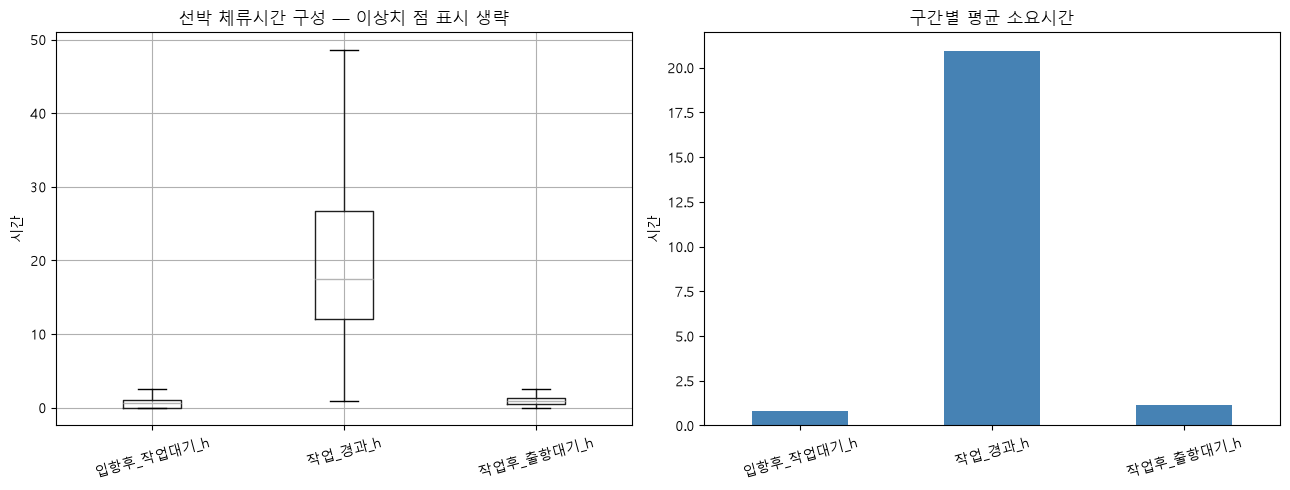

In [143]:

time_summary = voyage_df[time_cols].agg(
    ["count", "mean", "median", "std", "min", "max"]
).T


display(time_summary.round(2))


fig, axes = plt.subplots(1, 2, figsize=(13, 5))


voyage_df[time_cols[:3]].boxplot(ax=axes[0], showfliers=False)

axes[0].set_title("선박 체류시간 구성 — 이상치 점 표시 생략")

axes[0].set_ylabel("시간")
axes[0].tick_params(axis="x", rotation=15)

voyage_df[time_cols[:3]].mean().plot(
    kind="bar", stacked=False, ax=axes[1], color="steelblue"
)
axes[1].set_title("구간별 평균 소요시간")

axes[1].set_ylabel("시간")
axes[1].tick_params(axis="x", rotation=15)


plt.tight_layout()

plt.savefig(result_dir / "01_선박시간_구간비교.png", dpi=180)

plt.show()

### 2-2. 선박 작업량이 많을수록 작업시간도 길었을까?

모선항차 단위로 물동량과 작업 경과시간을 비교했다. 

상관관계는 두 변수가 함께 달라지는 정도를 보여 주며 인과관계를 의미하지는 않는다.

,변수_X,변수_Y,항차수,Pearson_r
0,양하량,작업_경과_h,753,0.857
1,선적량,작업_경과_h,753,0.767
2,총작업량,작업_경과_h,753,0.935
3,Shift_물량,작업_경과_h,753,0.497


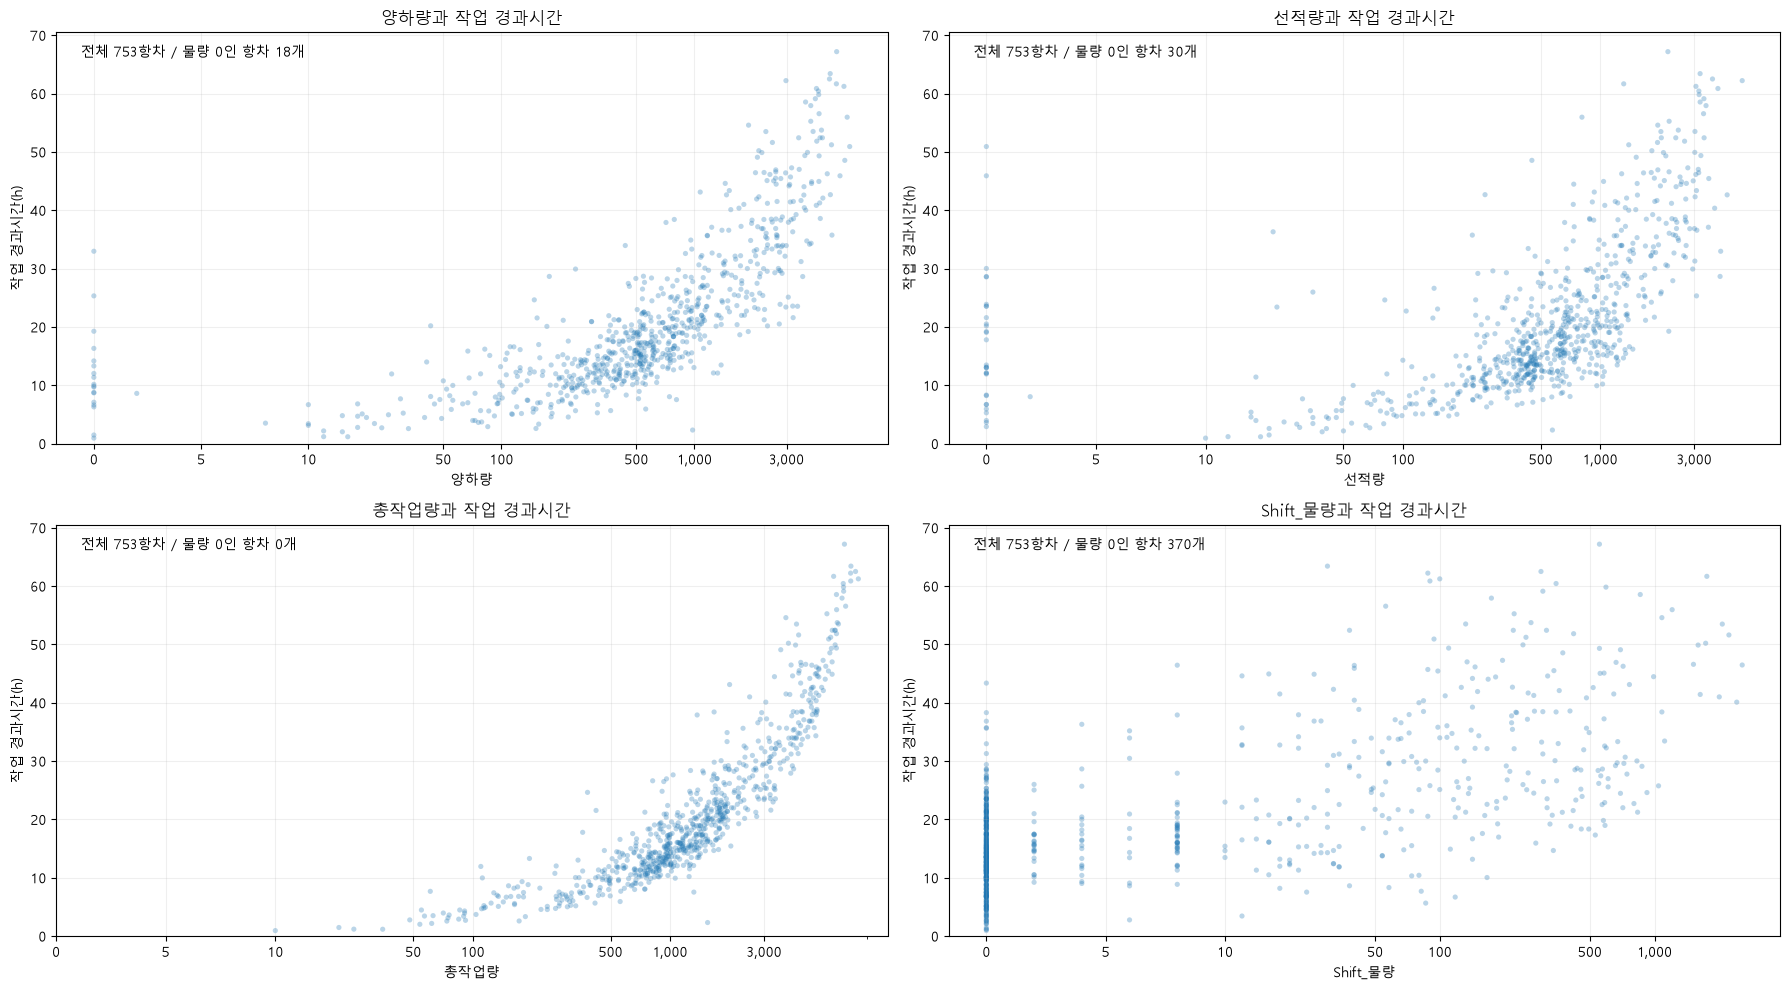

In [144]:
def correlation_table(frame, pairs):
    rows = []

   
    for x, y in pairs:
        sample = (
            frame[[x, y]]
            .replace([np.inf, -np.inf], np.nan)
            .dropna()
        )

        valid = (
            len(sample) >= 3
            and sample[x].nunique() > 1
            and sample[y].nunique() > 1
        )

        
        rows.append({
            "변수_X": x,
            "변수_Y": y,
            "항차수": len(sample),
            "Pearson_r": (
                sample[x].corr(sample[y]) if valid else np.nan
            ),
        })

    
    return pd.DataFrame(rows)




time_col = "작업_경과_h"

volume_cols = ["양하량", "선적량", "총작업량", "Shift_물량"]

volume_corr = correlation_table(
    voyage_df,
    [(col, time_col) for col in volume_cols],
)

display(volume_corr.round(3))






fig, axes = plt.subplots(2, 2, figsize=(18, 10))

for ax, col in zip(axes.flat, volume_cols):
   
    sample = (
        voyage_df[[col, "작업_경과_h"]]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    ax.scatter(
        sample[col],
        sample["작업_경과_h"],
        alpha=0.3,       
        s=14,            
        edgecolors="none",
    )

    
    ax.set_xscale("symlog", linthresh=10)

    
    ticks = [0, 5, 10, 50, 100, 500, 1000, 3000, 10000]
    max_value = sample[col].max()
    ticks = [value for value in ticks if value <= max_value]

    ax.set_xticks(ticks)
    ax.set_xticklabels([f"{value:,}" for value in ticks])

    zero_count = sample[col].eq(0).sum()

    ax.set_xlabel(f"{col}")
    ax.set_ylabel("작업 경과시간(h)")
    ax.set_title(f"{col}과 작업 경과시간")

    
    ax.text(
        0.03, 0.97,
        f"전체 {len(sample):,}항차 / 물량 0인 항차 {zero_count:,}개",
        transform=ax.transAxes,
        va="top",
        fontsize=10,
    )

    ax.grid(True, alpha=0.2)
    ax.set_ylim(bottom=0)

plt.tight_layout()
plt.savefig(
    result_dir / "02물량과작업시간가로축조정.png",
    dpi=180,
)
plt.show()

In [145]:
print(voyage_df.columns.tolist())

['모선항차', '선박명', '선석', '선사', '항로', '선박_입항일시', '선박_출항일시', '선박_작업시작일시', '선박_작업완료일시', '양하량', '선적량', 'Shift_물량', '입항후_작업대기_h', '작업_경과_h', '작업후_출항대기_h', '선박_체류_h', '총작업량']


### 2-3. 선석·선사·항로별 운영시간 비교

선석·선사·항로별 운영시간의 차이를 확인했다. 분포 차이는 선박 크기, 작업량, 운영일정의 차이와 함께 해석해야 한다.

,항차수,평균작업시간_h,중앙작업시간_h,평균총작업량
선석,,,,
2B,286,14.54,13.71,987.55
1B,215,25.57,22.58,2561.49
3B,154,26.80,23.72,2878.75
4B,98,20.14,18.48,1577.56


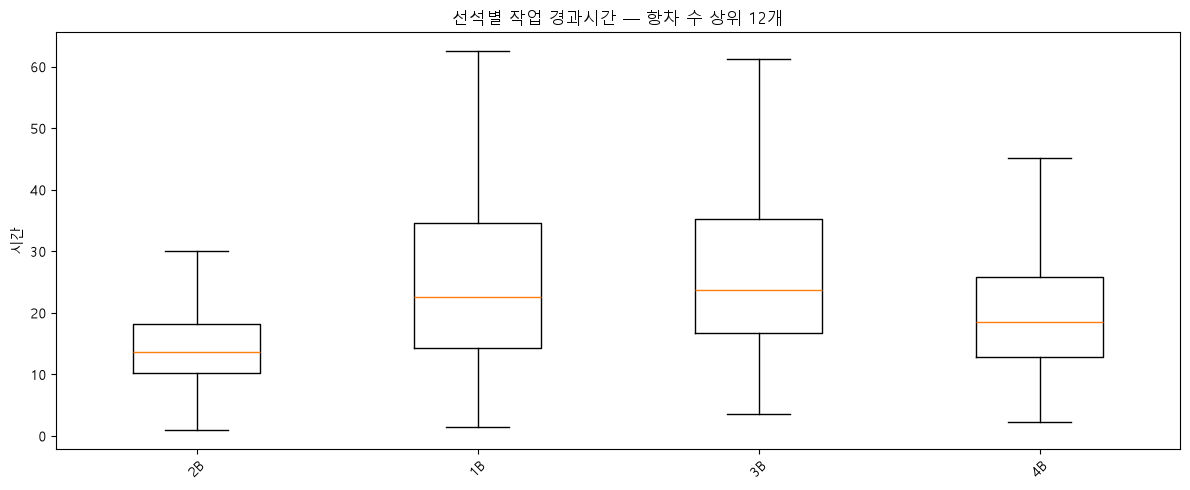

,항차수,평균작업시간_h,중앙작업시간_h,평균총작업량
선사,,,,
ONE,236,20.86,16.85,1872.78
BEN,107,16.21,15.93,1058.88
HMM,98,35.16,32.79,3800.97
YML,81,22.77,20.18,2321.20
SML,31,15.84,14.78,1071.48
HLC,28,38.29,40.55,3993.79
SKR,27,8.78,6.67,505.89
KFC,26,6.56,6.23,291.92
HAS,24,6.59,5.75,310.33


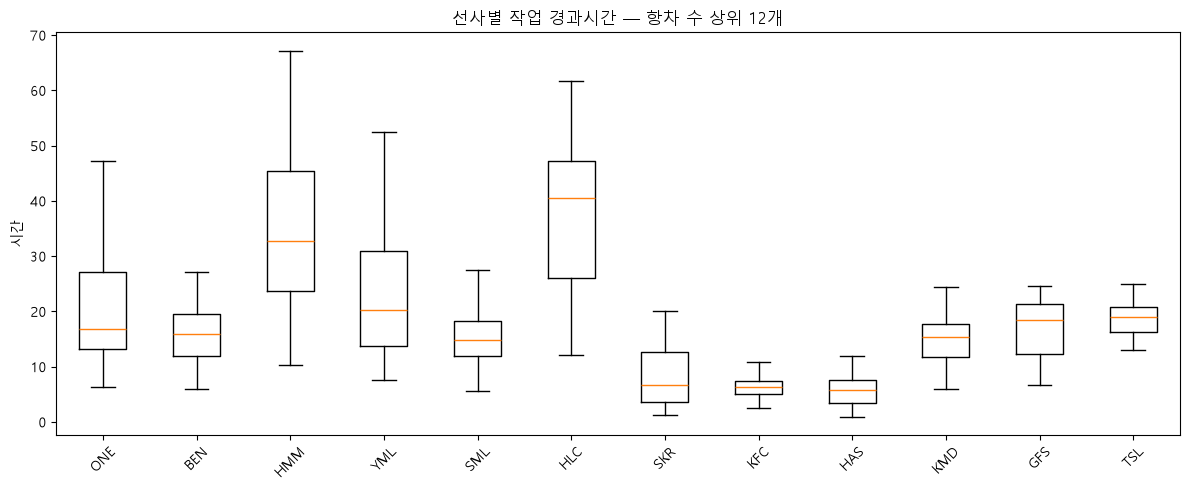

,항차수,평균작업시간_h,중앙작업시간_h,평균총작업량
항로,,,,
JK2,49,14.81,14.18,900.90
EC4E,43,18.51,17.30,1634.98
JVH,41,13.33,12.73,746.15
FE3,40,42.49,38.58,5622.65
BH3,39,19.88,19.88,1561.23
PN3E,37,17.39,14.83,1460.57
BNX,37,11.41,10.72,455.11
AIS,36,15.81,16.40,1248.83
SIS2,34,16.53,17.82,1366.94


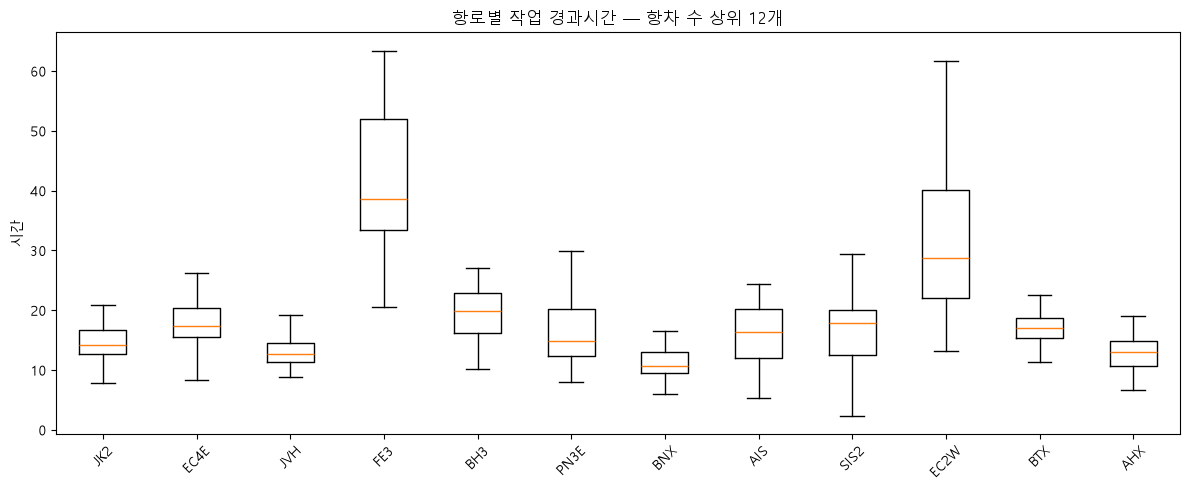

In [146]:

category_tables = {}


for col in ["선석", "선사", "항로"]:
    table = (
        voyage_df.groupby(col, dropna=False)
        .agg(
            항차수=("모선항차", "size"),
            평균작업시간_h=("작업_경과_h", "mean"),
            중앙작업시간_h=("작업_경과_h", "median"),
            평균총작업량=("총작업량", "mean"),
        )
        .sort_values("항차수", ascending=False)
    )

    category_tables[col] = table
    
    display(table.round(2))

   
    table.to_csv(
        result_dir / f"{col}별_작업시간.csv",
        encoding="utf-8-sig",
    )

    
    selected = table.head(12).index
    groups = [
        voyage_df.loc[
            voyage_df[col].eq(value), "작업_경과_h"
        ].dropna()
       
        for value in selected
    ]

    #
    fig, ax = plt.subplots(figsize=(12, 5))
    #
    ax.boxplot(groups, showfliers=False)
    ax.set_xticks(range(1, len(selected) + 1))
    ax.set_xticklabels([str(v) for v in selected], rotation=45)
   
    ax.set_title(f"{col}별 작업 경과시간 — 항차 수 상위 12개")
    
    ax.set_ylabel("시간")
    
    plt.tight_layout()
    
    plt.savefig(result_dir / f"03_{col}별_작업시간.png", dpi=180)
    
    plt.show()

### 2-4. 선박 항차와 컨테이너를 연결했다

컨테이너 기록을 항차별 양하·적하로 묶고 선박 운영시간을 연결했다.

 이 부분의 `HJNC_체류_h`는 **HJNC 반입→반출 시간**이며, 이후 사용하는 **장치→온샤시 야드 체류시간**과는 다르다.

In [147]:
container_df = container_df.loc[
    container_df["모선항차"].isin(voyage_df["모선항차"])
].copy()

container_df["HJNC_체류_h"] = (
    container_df["HJNC_반출시간"] - container_df["HJNC_반입시간"]
).dt.total_seconds() / 3600


assert np.allclose(
    container_df["HJNC_체류_h"],
    container_df["HJNC_체류분"] / 60,
    equal_nan=True,
)


if (
    container_df["HJNC_체류_h"].isna().any()
    or container_df["HJNC_체류_h"].lt(0).any()
):
   
    raise ValueError("컨테이너 체류시간 누락 또는 음수를 확인하세요.")


assert container_df["원본_데이터행번호"].is_unique


container_stats = (
    container_df.groupby(["모선항차", "HJNC_구분"])
    .agg(
        연결기록수=("원본_데이터행번호", "size"),
        평균체류_h=("HJNC_체류_h", "mean"),
        중앙체류_h=("HJNC_체류_h", "median"),
    )
    .reset_index()
)


linked_df = container_stats.merge(
    voyage_df,
    on="모선항차",
    how="left",
    validate="many_to_one",
)


display(
    linked_df[
        [
            "모선항차", "선박명", "HJNC_구분",
            "작업_경과_h", "선박_체류_h",
            "연결기록수", "평균체류_h", "중앙체류_h",
        ]
    ].head(10)
)

,모선항차,선박명,HJNC_구분,작업_경과_h,선박_체류_h,연결기록수,평균체류_h,중앙체류_h
0,AKTR-2025-0001,AKITA TRADER,양하,6.816667,6.916667,1,50.950000,50.950000
1,ANFL-2025-0001,CMA CGM FIORDLAND,양하,20.416667,22.500000,13,138.437179,141.266667
2,ANZG-2025-0001,CMA CGM ZINGARO,양하,23.533333,25.716667,2,101.633333,101.633333
3,ATSH-2025-0001,ATLANTIC SOUTH,양하,8.816667,11.916667,2,176.316667,176.316667
4,BASX-2025-0001,BASLE EXPRESS,양하,45.900000,48.583333,141,317.269740,289.566667
5,BGKX-2025-0001,BANGKOK EXPRESS,적하,19.250000,19.333333,14,241.813095,347.316667
6,BIGE-2025-0001,BIG GEORGE,양하,27.116667,27.750000,14,157.889286,4.975000
7,BIGE-2025-0002,BIG GEORGE,양하,26.750000,26.750000,8,365.266667,368.041667
8,BIGE-2025-0002,BIG GEORGE,적하,26.750000,26.750000,72,23.811806,24.225000
9,BIGE-2025-0003,BIG GEORGE,양하,27.116667,29.000000,71,200.199531,204.800000


### 2-5. 선박 시간과 HJNC 반입·반출 체류시간 비교

선박 시간과 컨테이너의 HJNC 반입·반출 체류시간 사이의 상관을 양하·적하별로 비교했다.

 이 결과는 뒤의 두 터미널 야드 체류 합계 분석과 구분한다.

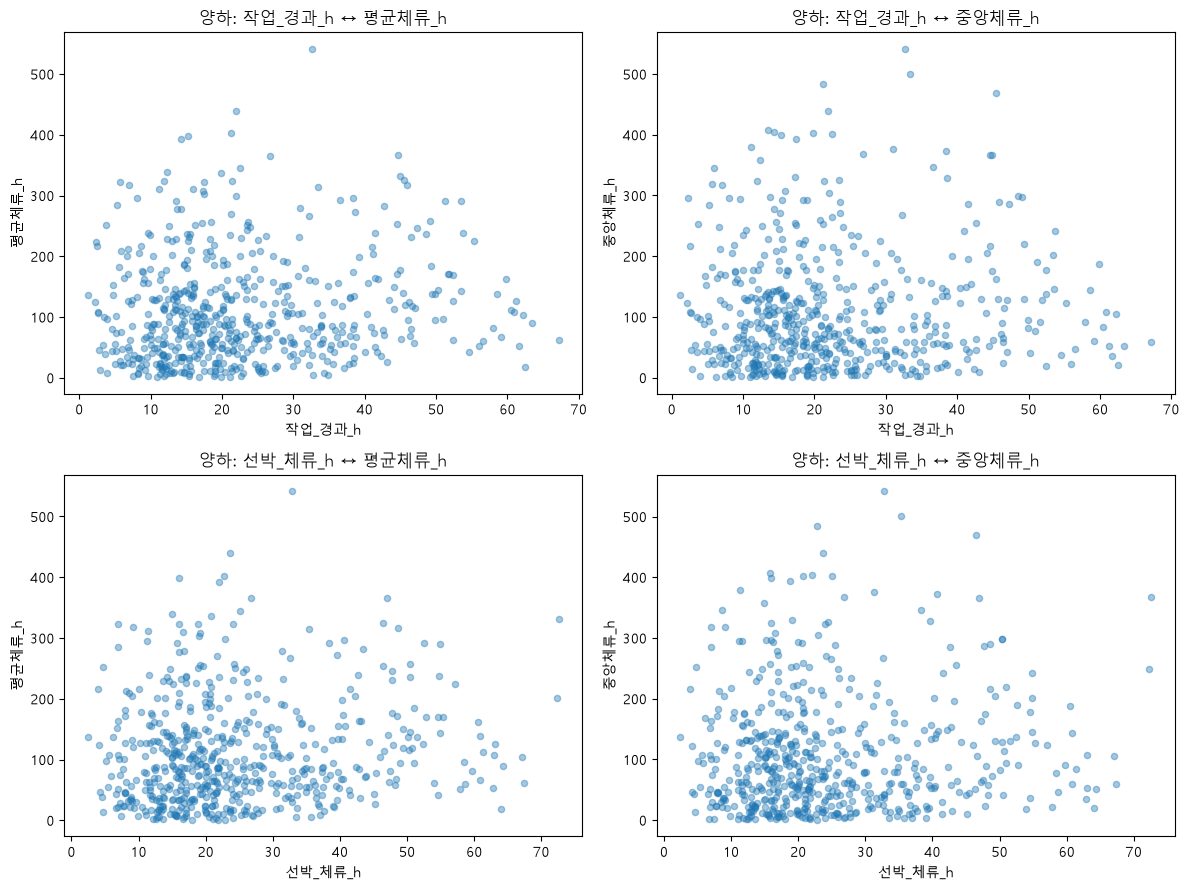

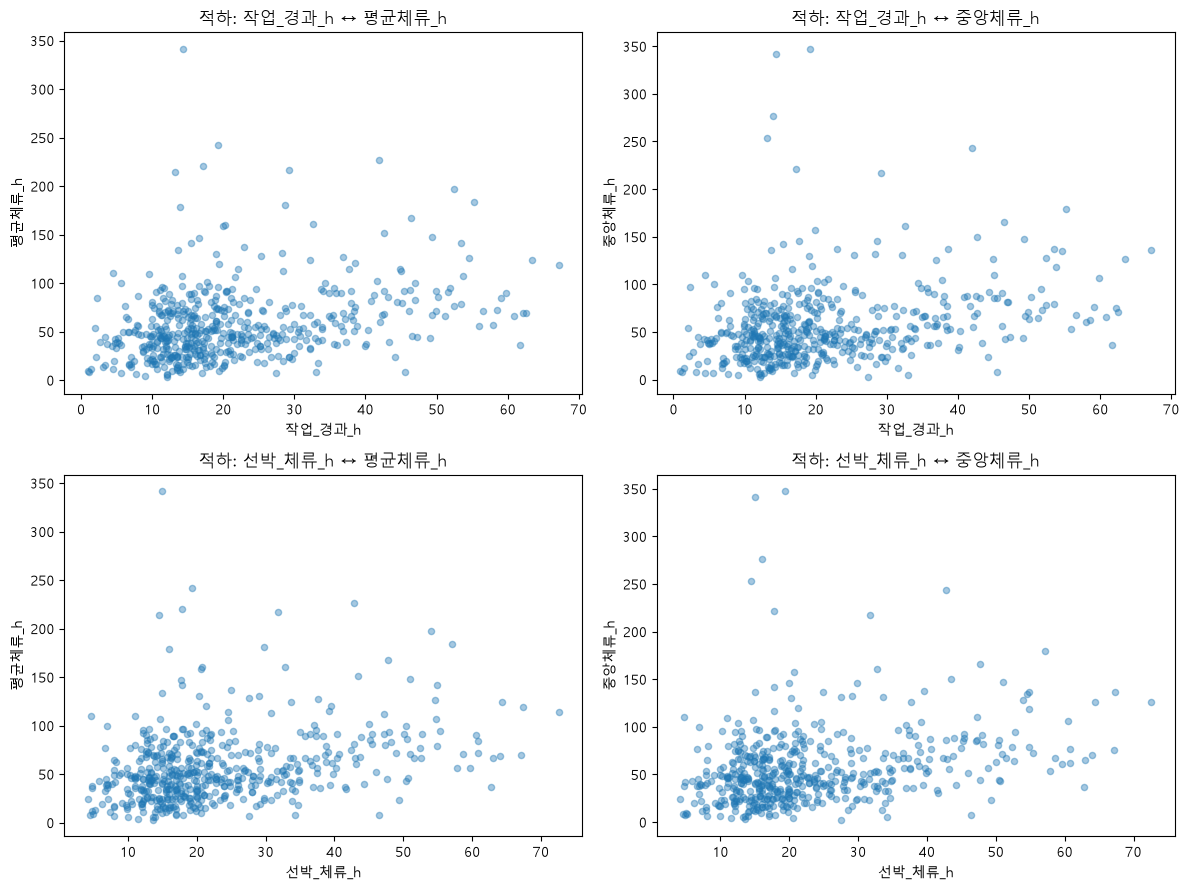

,HJNC_구분,변수_X,변수_Y,항차수,Pearson_r
0,양하,작업_경과_h,평균체류_h,577,0.107
1,양하,작업_경과_h,중앙체류_h,577,0.045
2,양하,선박_체류_h,평균체류_h,577,0.123
3,양하,선박_체류_h,중앙체류_h,577,0.065
4,적하,작업_경과_h,평균체류_h,522,0.326
5,적하,작업_경과_h,중앙체류_h,522,0.287
6,적하,선박_체류_h,평균체류_h,522,0.322
7,적하,선박_체류_h,중앙체류_h,522,0.284


In [148]:

relationship_pairs = [
    ("작업_경과_h", "평균체류_h"),
    ("작업_경과_h", "중앙체류_h"),
    ("선박_체류_h", "평균체류_h"),
    ("선박_체류_h", "중앙체류_h"),
]

relationship_results = []


for direction in ["양하", "적하"]:
    sample = linked_df.loc[linked_df["HJNC_구분"].eq(direction)]

    table = correlation_table(sample, relationship_pairs)
   
    table.insert(0, "HJNC_구분", direction)
    
    relationship_results.append(table)

   
    fig, axes = plt.subplots(2, 2, figsize=(12, 9))

    
    for ax, (x, y) in zip(axes.flat, relationship_pairs):
       
        ax.scatter(sample[x], sample[y], alpha=0.4, s=20)
        
        ax.set_xlabel(x)
        
        ax.set_ylabel(y)
       
        ax.set_title(f"{direction}: {x} ↔ {y}")

   
    plt.tight_layout()
   
    plt.savefig(
        result_dir / f"04_{direction}_선박시간과_컨테이너체류.png",
        dpi=180,
    )
   
    plt.show()


relationship_corr = pd.concat(
    relationship_results, ignore_index=True
)

display(relationship_corr.round(3))

### 2-6. 선박 체류시간 구간별 차이

선박 전체 체류시간을 0~12, 12~24, 24~36, 36시간 이상 구간으로 나눠 각 구간의 컨테이너 체류시간을 비교했다.

,HJNC_구분,선박체류구간,항차수,컨테이너기록수,항차기준_평균체류시간_h,항차중앙값의중앙값_h,컨테이너기준_평균체류시간h,전체컨테이너중앙h
0,양하,0~12시간 미만,77,454,102.72,78.02,112.39,97.43
1,양하,12~24시간 미만,270,7719,104.32,83.88,106.94,82.15
2,양하,24~36시간 미만,121,4442,110.99,62.13,119.08,78.57
3,양하,36시간 이상,109,7465,127.14,89.22,120.69,83.42
4,적하,0~12시간 미만,65,962,40.27,38.72,39.70,37.26
5,적하,12~24시간 미만,277,9377,52.84,44.82,49.70,41.98
6,적하,24~36시간 미만,97,3988,57.79,45.72,65.72,49.08
7,적하,36시간 이상,83,3789,82.81,73.05,73.18,63.45


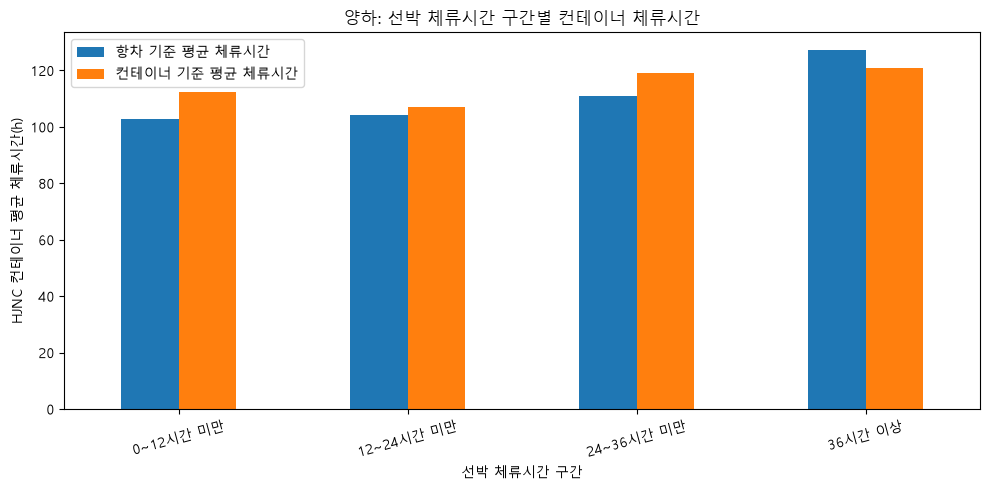

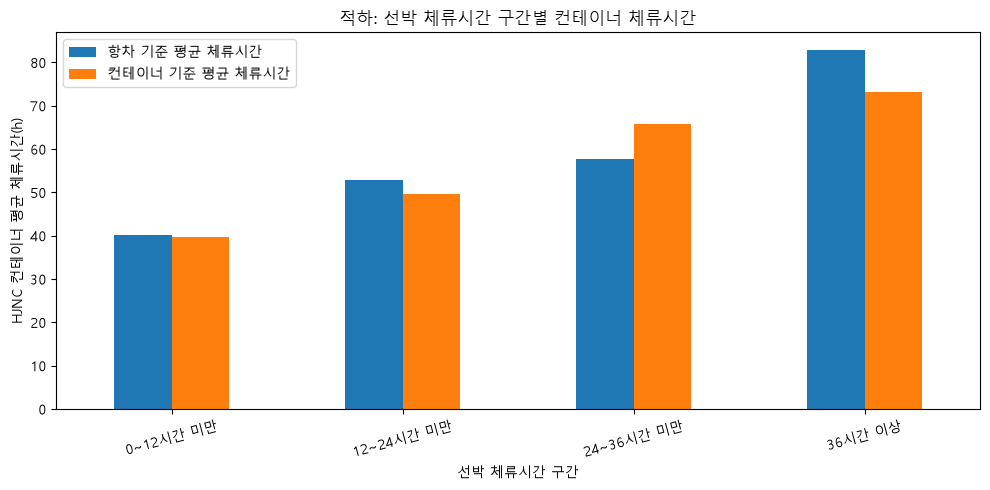

In [149]:
bins = [0, 12, 24, 36, np.inf]
labels = [
    "0~12시간 미만",
    "12~24시간 미만",
    "24~36시간 미만",
    "36시간 이상",
]

linked_df["선박체류구간"] = pd.cut(
    linked_df["선박_체류_h"],
    bins=bins,
    labels=labels,
    right=False,
)


bin_voyage = (
    linked_df.groupby(
        ["HJNC_구분", "선박체류구간"],
        observed=True,
    )
    .agg(
        항차수=("모선항차", "size"),
        컨테이너기록수=("연결기록수", "sum"),
        항차기준_평균체류시간_h=("평균체류_h", "mean"),
        항차중앙값의중앙값_h=("중앙체류_h", "median"),
    )
    .reset_index()
)


container_bins = container_df.merge(
    voyage_df[["모선항차", "선박_체류_h"]],
    on="모선항차",
    how="left",
    validate="many_to_one",
)

container_bins["선박체류구간"] = pd.cut(
    container_bins["선박_체류_h"],
    bins=bins,
    labels=labels,
    right=False,
)


bin_container = (
    container_bins.groupby(
        ["HJNC_구분", "선박체류구간"],
        observed=True,
    )
    .agg(
        컨테이너기준_평균체류시간h=("HJNC_체류_h", "mean"),
        전체컨테이너중앙h=("HJNC_체류_h", "median"),
    )
    .reset_index()
)


bin_summary = bin_voyage.merge(
    bin_container,
    on=["HJNC_구분", "선박체류구간"],
    validate="one_to_one",
)

display(bin_summary.round(2))


for direction in ["양하", "적하"]:
    plot_data = (
        bin_summary.loc[bin_summary["HJNC_구분"].eq(direction)]
        .set_index("선박체류구간")
        .reindex(labels)
    )

    ax = plot_data[
        [
            "항차기준_평균체류시간_h",
            "컨테이너기준_평균체류시간h",
        ]
    ].plot.bar(figsize=(10, 5))

    ax.legend([
        "항차 기준 평균 체류시간",
        "컨테이너 기준 평균 체류시간",
    ])

    ax.set_title(f"{direction}: 선박 체류시간 구간별 컨테이너 체류시간")
    ax.set_xlabel("선박 체류시간 구간")
    ax.set_ylabel("HJNC 컨테이너 평균 체류시간(h)")
    plt.xticks(rotation=15)

    plt.tight_layout()
    plt.savefig(
        result_dir / f"05{direction}선박체류구간별비교.png",
        dpi=180,
    )
    plt.show()

### 2-7. 분석 중간 결과 저장

선박 항차별 통계와 컨테이너 연결 표를 CSV로 저장하도록 구성했다.

In [150]:

outputs = {
    "분석대상_컨테이너.csv": container_df,
    "항차당한행_선박분석표.csv": voyage_df,
    "항차별_양하적하_연결분석표.csv": linked_df,
    "선박시간_기술통계.csv": time_summary.reset_index(
        names="시간구간"
    ),
    "물량과_작업시간_상관계수.csv": volume_corr,
    "선박시간과_컨테이너체류_상관계수.csv": relationship_corr,
    "선박체류구간별_비교.csv": bin_summary,
}


for filename, table in outputs.items():
    
    table.to_csv(
        result_dir / filename,
        index=False,
        encoding="utf-8-sig",
    )


print("결과 저장 위치:", result_dir.resolve())

결과 저장 위치: C:\eda\results


## 3. 선박 시간 지표와 데이터 연결 확인

선박별 운영시간과 컨테이너별 야드 체류시간을 비교하려면 먼저 기준이 되는 항차와 컨테이너의 연결이 올바른지 확인해야 한다.
 
아래 단계에서는 선박 시간 정의와 두 터미널의 방문 기록 연결 기준을 정리했다.

In [151]:
print("voyage_df 컬럼 목록")
print(voyage_df.columns.tolist())

print("\n현재 데이터프레임 변수 목록")


for name, value in globals().copy().items():
    if isinstance(value, pd.DataFrame):
        print(name, value.shape)

voyage_df 컬럼 목록
['모선항차', '선박명', '선석', '선사', '항로', '선박_입항일시', '선박_출항일시', '선박_작업시작일시', '선박_작업완료일시', '양하량', '선적량', 'Shift_물량', '입항후_작업대기_h', '작업_경과_h', '작업후_출항대기_h', '선박_체류_h', '총작업량']

현재 데이터프레임 변수 목록
_ (38208, 40)
df (38208, 40)
_3 (38285, 40)
clean (38249, 40)
_15 (38285, 40)
_19 (38249, 40)
_20 (38172, 40)
raw (38285, 40)
_26 (38285, 40)
_30 (38249, 40)
_31 (38172, 40)
_35 (38208, 40)
cleaned (38249, 40)
container_df (38196, 41)
conflicts (753, 11)
voyage_df (753, 17)
time_summary (4, 6)
volume_corr (4, 4)
sample (522, 21)
table (8, 8)
container_stats (1099, 5)
linked_df (1099, 22)
_48 (38285, 40)
_52 (38249, 40)
_53 (38172, 40)
_57 (38208, 40)
relationship_corr (8, 5)
bin_voyage (8, 6)
container_bins (38196, 43)
bin_container (8, 4)
bin_summary (8, 8)
plot_data (4, 7)
_71 (38285, 40)
_75 (38249, 40)
_76 (38172, 40)
_80 (38208, 40)
analysis_df (753, 24)
schedule_time (755, 3)
summary (5, 6)
_100 (38285, 40)
_104 (38249, 40)
_105 (38172, 40)
_109 (38208, 40)
pair_df (38299, 69)
yard_df

In [152]:


for name in ["raw", "clean", "cleaned", "container_df", "voyage_df"]:
    if name not in globals():
        continue

    df = globals()[name]

    print(f"\n========== {name} ==========")

    cols = [
        col for col in df.columns
        if any(keyword in str(col)
               for keyword in ["반입", "마감", "입항", "출항", "모선항차"])
    ]

    print("관련 컬럼:", cols)


========== raw ==========
관련 컬럼: ['모선항차', '선박_입항일시', '선박_출항일시', '스케줄_반입시작일시', '스케줄_반입마감일시', 'HJNC_반입방식', 'HJNC_반입시간', 'DGT_반입시간', '입출항시간_검증상태', '입항후_경과분', '출항까지_잔여분', '적하컨테이너_반입기간비교', '적하컨테이너_마감초과분', '입항후_작업대기시간_h', '작업완료후_출항대기시간_h']

========== clean ==========
관련 컬럼: ['모선항차', '선박_입항일시', '선박_출항일시', '스케줄_반입시작일시', '스케줄_반입마감일시', 'HJNC_반입방식', 'HJNC_반입시간', 'DGT_반입시간', '입출항시간_검증상태', '입항후_경과분', '출항까지_잔여분', '적하컨테이너_반입기간비교', '적하컨테이너_마감초과분', '입항후_작업대기시간_h', '작업완료후_출항대기시간_h']

========== cleaned ==========
관련 컬럼: ['모선항차', '선박_입항일시', '선박_출항일시', '스케줄_반입시작일시', '스케줄_반입마감일시', 'HJNC_반입방식', 'HJNC_반입시간', 'DGT_반입시간', '입출항시간_검증상태', '입항후_경과분', '출항까지_잔여분', '적하컨테이너_반입기간비교', '적하컨테이너_마감초과분', '입항후_작업대기시간_h', '작업완료후_출항대기시간_h']

========== container_df ==========
관련 컬럼: ['모선항차', '선박_입항일시', '선박_출항일시', '스케줄_반입시작일시', '스케줄_반입마감일시', 'HJNC_반입방식', 'HJNC_반입시간', 'DGT_반입시간', '입출항시간_검증상태', '입항후_경과분', '출항까지_잔여분', '적하컨테이너_반입기간비교', '적하컨테이너_마감초과분', '입항후_작업대기시간_h', '작업완료후_출항대기시간_h']

========== voyage_df ==========
관련 컬럼: ['모선항

반입시각이 여러 개 존재하는 항차: 0
========== 선박 시간 지표 5개 ==========


,분석건수,평균시간,중앙값,표준편차,최소시간,최대시간
입항 지연시간,753.0,83.17,82.17,6.66,71.75,95.67
작업시작전 대기시간,753.0,0.81,0.58,1.69,0.00,26.93
작업시간,753.0,20.93,17.50,12.61,0.93,67.18
작업 후 출항 대기시간,753.0,1.12,0.92,2.37,0.00,60.63
출항 지연시간,753.0,33.09,30.00,12.90,12.00,83.00


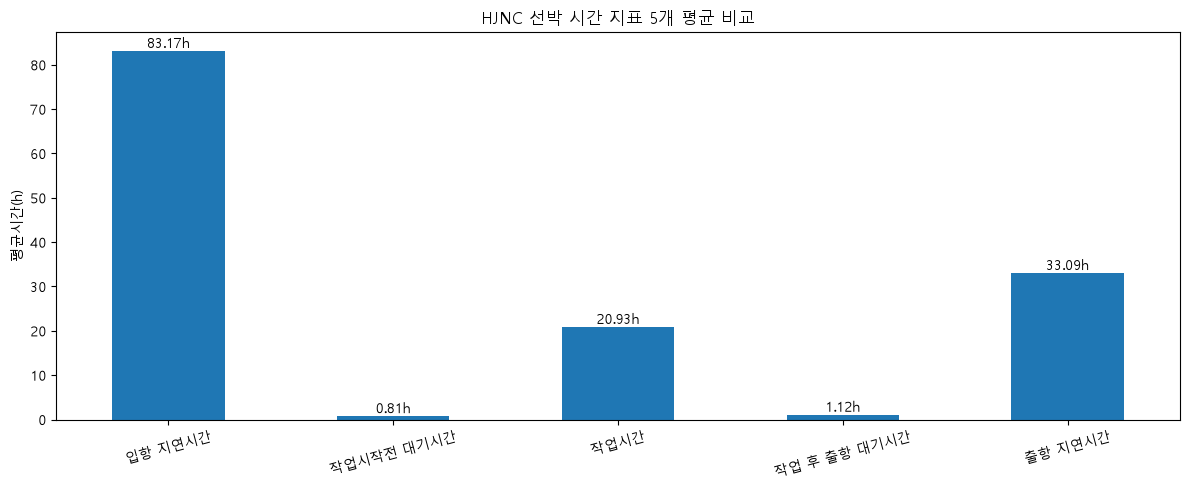

In [153]:



analysis_df = voyage_df.copy()



schedule_time = (
    cleaned[
        [
            "모선항차",
            "스케줄_반입시작일시",
            "스케줄_반입마감일시"
        ]
    ]
    .drop_duplicates()
    .copy()
)


conflict_counts = (
    schedule_time.groupby("모선항차", dropna=False)
    .size()
)

conflict_voyages = conflict_counts[conflict_counts > 1]

print("반입시각이 여러 개 존재하는 항차:",
      len(conflict_voyages))


if not conflict_voyages.empty:
    raise ValueError(
        "동일 모선항차에 반입 시작/마감 시각이 여러 개 있습니다. "
        "원본 스케줄 확인이 필요합니다."
    )

analysis_df = analysis_df.merge(
    schedule_time,
    on="모선항차",
    how="left",
    validate="one_to_one"
)



date_cols = [
    "선박_입항일시",
    "선박_출항일시",
    "선박_작업시작일시",
    "선박_작업완료일시",
    "스케줄_반입시작일시",
    "스케줄_반입마감일시"
]

for col in date_cols:
    analysis_df[col] = pd.to_datetime(
        analysis_df[col],
        errors="coerce"
    )


formulas = {
    "입항 지연시간": (
        "선박_입항일시",
        "스케줄_반입시작일시"
    ),
    "작업시작전 대기시간": (
        "선박_작업시작일시",
        "선박_입항일시"
    ),
    "작업시간": (
        "선박_작업완료일시",
        "선박_작업시작일시"
    ),
    "작업 후 출항 대기시간": (
        "선박_출항일시",
        "선박_작업완료일시"
    ),
    "출항 지연시간": (
        "선박_출항일시",
        "스케줄_반입마감일시"
    )
}

for name, (end, start) in formulas.items():
    analysis_df[name] = (
        analysis_df[end] - analysis_df[start]
    ).dt.total_seconds() / 3600

time_cols = list(formulas.keys())



summary = analysis_df[time_cols].agg(
    ["count", "mean", "median", "std", "min", "max"]
).T

summary.columns = [
    "분석건수",
    "평균시간",
    "중앙값",
    "표준편차",
    "최소시간",
    "최대시간"
]

print("========== 선박 시간 지표 5개 ==========")
display(summary.round(2))



ax = summary["평균시간"].plot.bar(
    figsize=(12, 5),
    rot=15
)

ax.set_title("HJNC 선박 시간 지표 5개 평균 비교")
ax.set_xlabel("")
ax.set_ylabel("평균시간(h)")

for i, value in enumerate(summary["평균시간"]):
    ax.text(
        i,
        value,
        f"{value:.2f}h",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


### 3-1. 선박 시간 지표 5개를 어떻게 계산했을까?

| 지표 | 계산식 | 해석 |
|:---|:---|:---|
| 입항 지연시간(대체지표) | 선박 입항 − 스케줄 반입시작 | 실제 입항 지연과는 다른 경과시간 |
| 작업시작전 대기시간 | 작업 시작 − 선박 입항 | 입항 후 작업 전 시간 |
| 작업시간 | 작업 완료 − 작업 시작 | 작업 구간 경과시간 |
| 작업 후 출항 대기시간 | 선박 출항 − 작업 완료 | 작업 완료 후 경과시간 |
| 출항 지연시간(대체지표) | 선박 출항 − 스케줄 반입마감 | 실제 출항 지연과는 다른 경과시간 |

두 대체지표는 계획 입·출항 시각이 아니라 반입 시작·마감 시각을 사용했으므로 공식 지연시간으로 단정하지 않는다.

### 4-1. 두 터미널 체류시간 계산식

- **DGT 야드 체류시간(h)** = DGT 온샤시 시간 − DGT 야드 장치 시간
- **HJNC 야드 체류시간(h)** = HJNC 온샤시 시간 − HJNC 야드 장치 시간
- **총 야드 체류시간(h)** = DGT 야드 체류시간 + HJNC 야드 체류시간

**검증 결과:** 컨테이너 38,196건 모두 연결됐고 체류시간 결측·음수로 계산에서 제외한 행은 없었다. 합계 불일치도 0건이었다.

In [154]:


pair_df = pd.read_csv(
    "DGT_HJNC_PAIR_2025.csv",
    encoding="utf-8-sig",
    low_memory=False
)


yard_df = container_df.copy()


yard_df["_분석행ID"] = np.arange(len(yard_df))
pair_df["_PAIR행ID"] = np.arange(len(pair_df))



pair_cols = [
    "컨테이너번호",
    "환적방향",
    "HJNC_반입시간",
    "HJNC_반출시간",
    "야드 장치 시간",
    "온샤시 시간",
    "HJNC_야드 장치 시간",
    "HJNC_온샤시 시간",
]

base_cols = [
    "컨테이너번호",
    "환적방향",
    "HJNC_반입시간",
    "HJNC_반출시간",
]

for col in pair_cols:
    if col not in pair_df.columns:
        raise KeyError(f"PAIR 파일에 없는 컬럼: {col}")

for col in base_cols:
    if col not in yard_df.columns:
        raise KeyError(f"container_df에 없는 컬럼: {col}")



for df_temp in [yard_df, pair_df]:
    df_temp["컨테이너번호"] = (
        df_temp["컨테이너번호"]
        .astype("string")
        .str.strip()
        .str.upper()
    )

    df_temp["환적방향"] = (
        df_temp["환적방향"]
        .astype("string")
        .str.strip()
    )



for col in ["HJNC_반입시간", "HJNC_반출시간"]:
    yard_df[col] = pd.to_datetime(
        yard_df[col], errors="coerce"
    )

for col in [
    "HJNC_반입시간",
    "HJNC_반출시간",
    "야드 장치 시간",
    "온샤시 시간",
    "HJNC_야드 장치 시간",
    "HJNC_온샤시 시간",
]:
    pair_df[col] = pd.to_datetime(
        pair_df[col], errors="coerce"
    )



pair_select = pair_df[
    pair_cols + ["_PAIR행ID"]
].copy()

candidates = yard_df.merge(
    pair_select,
    on=["컨테이너번호", "환적방향"],
    how="left",
    suffixes=("", "_PAIR"),
    validate="many_to_many"
)


same_visit = (
    candidates["HJNC_반입시간"].eq(
        candidates["HJNC_반입시간_PAIR"]
    )
    &
    candidates["HJNC_반출시간"].eq(
        candidates["HJNC_반출시간_PAIR"]
    )
)

matched = candidates.loc[same_visit].copy()


match_counts = matched.groupby("_분석행ID").size()

unique_ids = match_counts[
    match_counts == 1
].index

matched = matched.loc[
    matched["_분석행ID"].isin(unique_ids)
].copy()



matched["DGT_야드체류시간_h"] = (
    matched["온샤시 시간"]
    - matched["야드 장치 시간"]
).dt.total_seconds() / 3600

matched["HJNC_야드체류시간_h"] = (
    matched["HJNC_온샤시 시간"]
    - matched["HJNC_야드 장치 시간"]
).dt.total_seconds() / 3600


valid_time = (
    matched["DGT_야드체류시간_h"].notna()
    &
    matched["HJNC_야드체류시간_h"].notna()
    &
    matched["DGT_야드체류시간_h"].ge(0)
    &
    matched["HJNC_야드체류시간_h"].ge(0)
)

matched = matched.loc[valid_time].copy()

matched["총_야드체류시간_h"] = (
    matched["DGT_야드체류시간_h"]
    + matched["HJNC_야드체류시간_h"]
)



result_cols = [
    "_분석행ID",
    "DGT_야드체류시간_h",
    "HJNC_야드체류시간_h",
    "총_야드체류시간_h",
]

yard_df = yard_df.merge(
    matched[result_cols],
    on="_분석행ID",
    how="left",
    validate="one_to_one"
)

yard_df = yard_df.drop(columns=["_분석행ID"])



print("========== 총 야드 체류시간 연결 결과 ==========")
print("기존 분석 컨테이너 행 수:", len(container_df))
print("방문 기록 일치 행 수:", len(unique_ids))
print("체류시간 계산 완료:", yard_df["총_야드체류시간_h"].notna().sum())
print("체류시간 미계산:", yard_df["총_야드체류시간_h"].isna().sum())
print("복수 방문 후보가 있는 행 수:", (match_counts > 1).sum())

display(
    yard_df[
        [
            "컨테이너번호",
            "모선항차",
            "환적방향",
            "DGT_야드체류시간_h",
            "HJNC_야드체류시간_h",
            "총_야드체류시간_h",
        ]
    ].head(10)
)


========== 총 야드 체류시간 연결 결과 ==========
기존 분석 컨테이너 행 수: 38196
방문 기록 일치 행 수: 38196
체류시간 계산 완료: 38196
체류시간 미계산: 0
복수 방문 후보가 있는 행 수: 0


,컨테이너번호,모선항차,환적방향,DGT_야드체류시간_h,HJNC_야드체류시간_h,총_야드체류시간_h
0,CAIU3395837,BIGE-2025-0001,HJNC→DGT,46.066667,3.916667,49.983333
1,CAIU4216010,BIGE-2025-0001,HJNC→DGT,28.616667,544.116667,572.733333
2,CXDU1586941,BIGE-2025-0001,HJNC→DGT,30.733333,4.883333,35.616667
3,FANU3857462,BIGE-2025-0001,HJNC→DGT,30.383333,543.033333,573.416667
4,HLBU1326594,BIGE-2025-0001,HJNC→DGT,29.316667,539.466667,568.783333
5,NYKU3652362,BIGE-2025-0001,HJNC→DGT,29.983333,5.566667,35.550000
6,SEGU1069546,BIGE-2025-0001,HJNC→DGT,45.533333,2.366667,47.900000
7,TCLU3649814,BIGE-2025-0001,HJNC→DGT,31.383333,4.733333,36.116667
8,TEMU0646980,BIGE-2025-0001,HJNC→DGT,45.700000,4.533333,50.233333
9,TEMU3602943,BIGE-2025-0001,HJNC→DGT,44.950000,0.583333,45.533333


**연결 결과:** 분석 대상 38,196건 모두 PAIR 방문기록과 한 번씩 일치했다. 총 야드 체류시간을 계산하지 못한 행은 없었다. 따라서 이후 방향별 비교에서는 동일한 38,196건을 사용했다.

In [155]:
print("기존 컨테이너 수:", len(container_df))
print("연결 후 컨테이너 수:", len(yard_df))

print(
    "총 야드 체류시간 계산 완료:",
    yard_df["총_야드체류시간_h"].notna().sum()
)

print(
    "총 야드 체류시간 미계산:",
    yard_df["총_야드체류시간_h"].isna().sum()
)

display(
    yard_df[
        [
            "DGT_야드체류시간_h",
            "HJNC_야드체류시간_h",
            "총_야드체류시간_h"
        ]
    ].describe().round(2)
)

기존 컨테이너 수: 38196
연결 후 컨테이너 수: 38196
총 야드 체류시간 계산 완료: 38196
총 야드 체류시간 미계산: 0


,DGT_야드체류시간_h,HJNC_야드체류시간_h,총_야드체류시간_h
count,38196.00,38196.00,38196.00
mean,139.66,87.45,227.11
std,366.02,91.59,370.04
min,0.00,0.03,0.88
25%,31.93,30.95,97.75
50%,59.92,58.07,158.82
75%,146.59,107.06,261.00
max,4037.87,1379.35,4116.25


## 4. 두 터미널의 야드 체류시간 연결

DGT와 HJNC에서 각각 `온샤시 − 야드 장치`로 계산한 시간을 합산했다. 같은 컨테이너번호가 반복될 수 있으므로 환적방향과 HJNC 반입·반출 일시가 일치하는 방문 기록만 연결했다.

In [156]:

import matplotlib.pyplot as plt



ship_time_cols = [
    "입항후_작업대기시간_h",
    "작업_경과시간_h",
    "작업완료후_출항대기시간_h",
    "선박_전체체류시간_h",
]

yard_time_col = "총_야드체류시간_h"

analysis_cols = [
    "컨테이너번호",
    "모선항차",
    yard_time_col,
] + ship_time_cols

corr_df = yard_df[analysis_cols].copy()


for col in [yard_time_col] + ship_time_cols:
    corr_df[col] = pd.to_numeric(
        corr_df[col],
        errors="coerce"
    )


corr_df = corr_df.dropna(
    subset=[yard_time_col]
)



results = []

for col in ship_time_cols:

    temp = corr_df[
        [yard_time_col, col]
    ].dropna()

    r = temp[yard_time_col].corr(
        temp[col],
        method="pearson"
    )

    results.append({
        "선박 시간 지표": col,
        "분석 컨테이너 수": len(temp),
        "피어슨 상관계수(r)": r,
    })

correlation_result = pd.DataFrame(results)

correlation_result["상관계수 절댓값"] = (
    correlation_result["피어슨 상관계수(r)"].abs()
)

correlation_result = correlation_result.sort_values(
    "상관계수 절댓값",
    ascending=False
).drop(columns="상관계수 절댓값")

print("========== 총 야드 체류시간과 선박 시간 상관관계 ==========")
print("분석 대상 컨테이너 수:", len(corr_df))

display(
    correlation_result.round(4)
)

========== 총 야드 체류시간과 선박 시간 상관관계 ==========
분석 대상 컨테이너 수: 38196


,선박 시간 지표,분석 컨테이너 수,피어슨 상관계수(r)
1,작업_경과시간_h,38196,0.0704
3,선박_전체체류시간_h,38196,0.0704
0,입항후_작업대기시간_h,38196,0.0400
2,작업완료후_출항대기시간_h,38196,-0.0197


In [157]:


ship_cols = [
    "입항 지연시간",
    "작업시작전 대기시간",
    "작업시간",
    "작업 후 출항 대기시간",
    "출항 지연시간"
]

yard_col = "총_야드체류시간_h"



ship_df = analysis_df[
    ["모선항차"] + ship_cols
].copy()

if ship_df["모선항차"].duplicated().any():
    raise ValueError("선박 시간 데이터에 중복 모선항차가 있습니다.")



corr_df = yard_df.merge(
    ship_df,
    on="모선항차",
    how="left",
    validate="many_to_one"
)


results = []

for col in ship_cols:

    temp = corr_df[
        [col, yard_col]
    ].copy()

    temp = temp.apply(
        pd.to_numeric,
        errors="coerce"
    ).dropna()

    r = temp[col].corr(
        temp[yard_col],
        method="pearson"
    )

    results.append({
        "선박 시간 지표": col,
        "분석 컨테이너 수": len(temp),
        "상관계수(r)": r
    })

correlation_result = pd.DataFrame(results)

print("========== 선박 시간 → 총 야드 체류시간 ==========")

print("기존 컨테이너 수:", len(yard_df))
print("연결 후 컨테이너 수:", len(corr_df))
print(
    "야드 체류시간 계산 완료:",
    corr_df[yard_col].notna().sum()
)

display(correlation_result.round(4))

========== 선박 시간 → 총 야드 체류시간 ==========
기존 컨테이너 수: 38196
연결 후 컨테이너 수: 38196
야드 체류시간 계산 완료: 38196


,선박 시간 지표,분석 컨테이너 수,상관계수(r)
0,입항 지연시간,38196,-0.1028
1,작업시작전 대기시간,38196,0.0400
2,작업시간,38196,0.0704
3,작업 후 출항 대기시간,38196,-0.0197
4,출항 지연시간,38196,0.0687


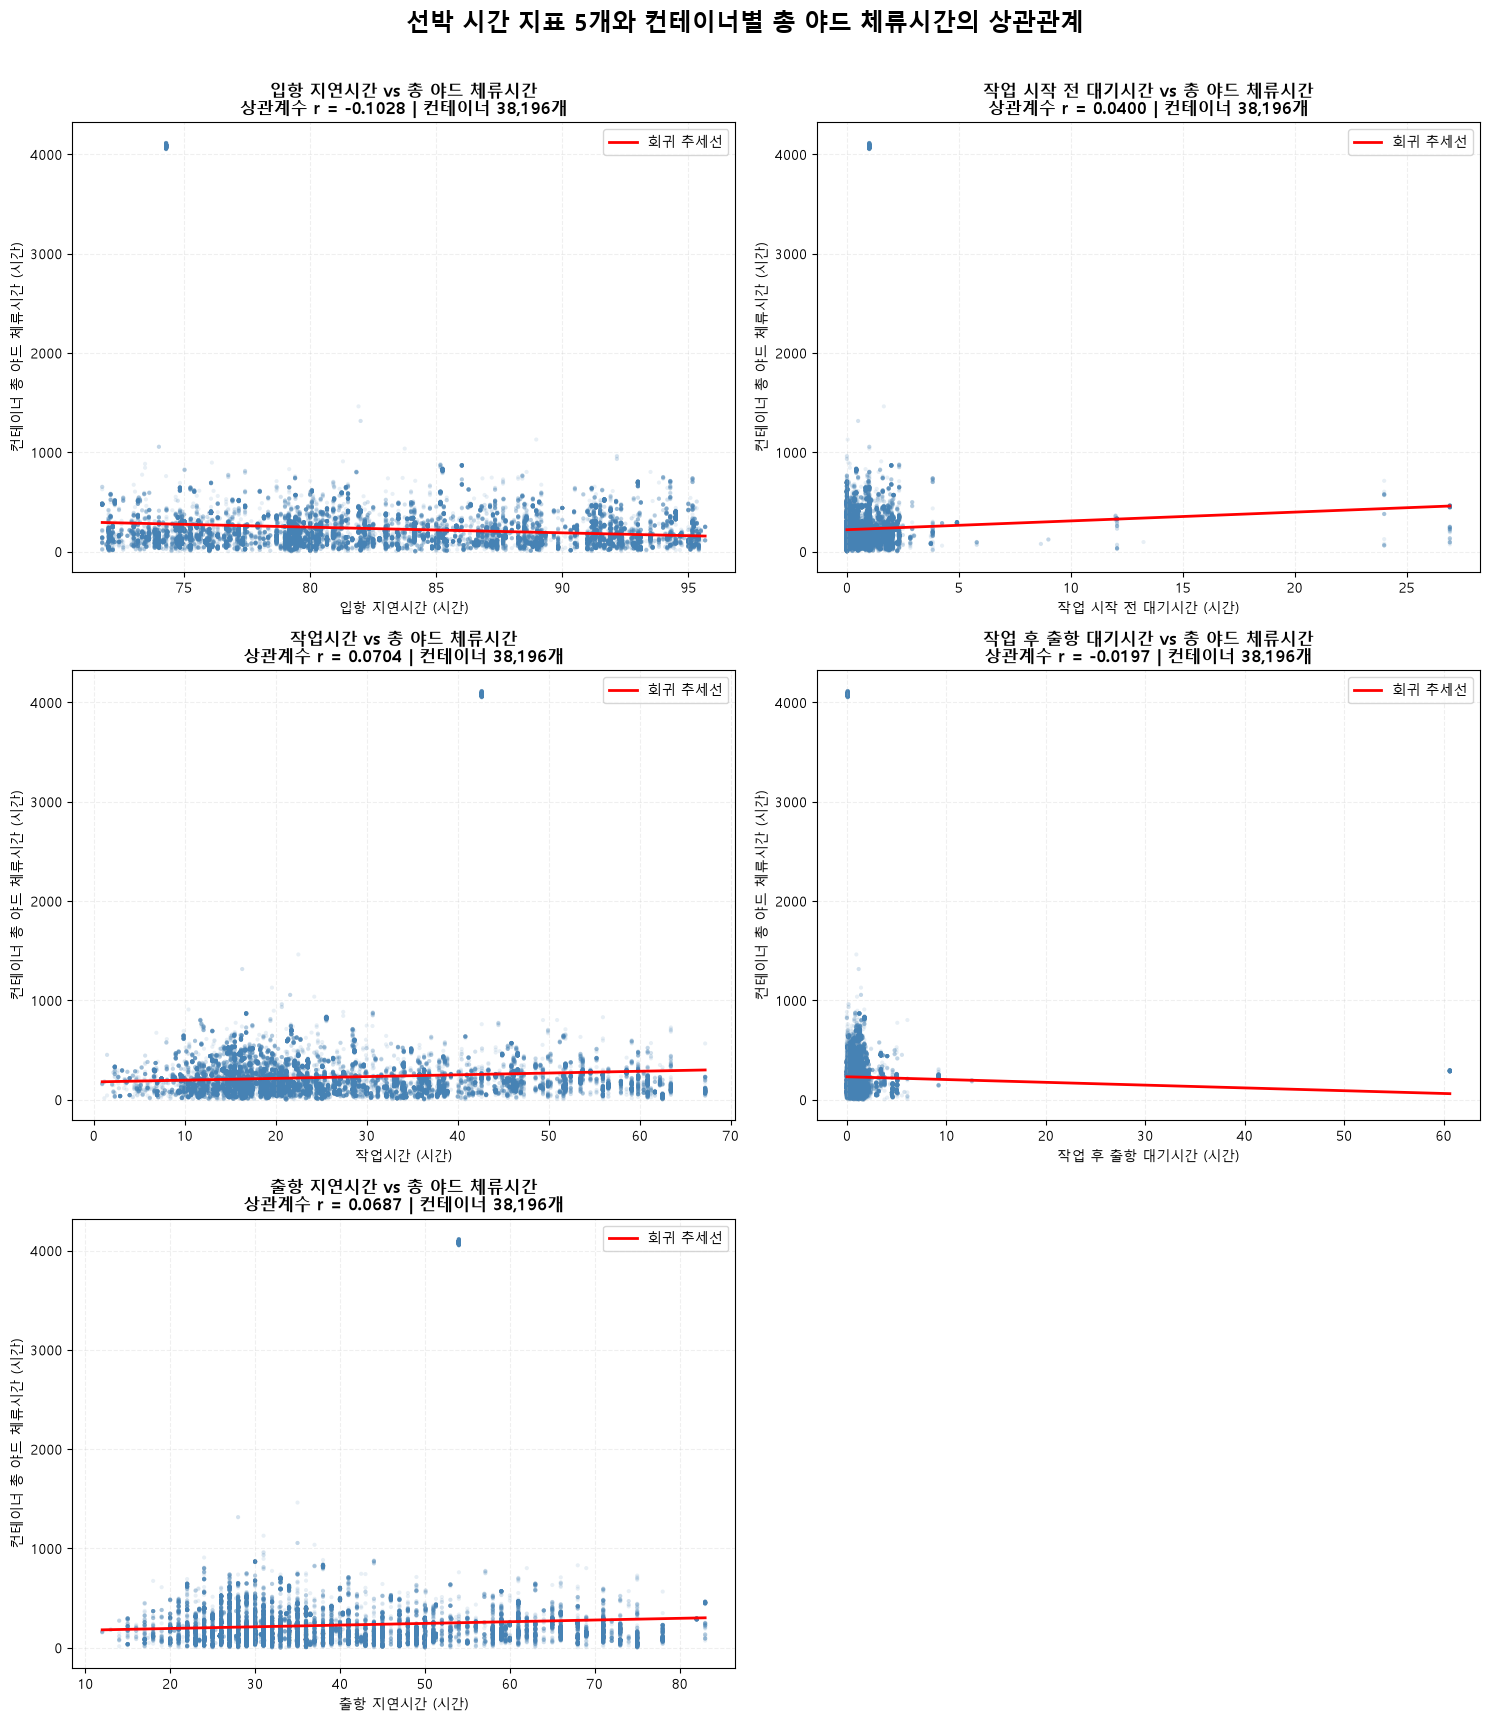

In [158]:


ship_cols = [
    "입항 지연시간",
    "작업시작전 대기시간",
    "작업시간",
    "작업 후 출항 대기시간",
    "출항 지연시간"
]

yard_col = "총_야드체류시간_h"


ship_labels = {
    "입항 지연시간": "입항 지연시간",
    "작업시작전 대기시간": "작업 시작 전 대기시간",
    "작업시간": "작업시간",
    "작업 후 출항 대기시간": "작업 후 출항 대기시간",
    "출항 지연시간": "출항 지연시간"
}


plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

fig, axes = plt.subplots(
    3, 2,
    figsize=(15, 17)
)

axes = axes.flatten()

for i, col in enumerate(ship_cols):

    ax = axes[i]

    
    temp = corr_df[
        [col, yard_col]
    ].copy()

    temp = temp.apply(
        pd.to_numeric,
        errors="coerce"
    ).dropna()

    x = temp[col].to_numpy()
    y = temp[yard_col].to_numpy()

    # 상관계수
    r = np.corrcoef(x, y)[0, 1]

   
    ax.scatter(
        x, y,
        alpha=0.12,
        s=9,
        color="steelblue",
        edgecolors="none"
    )

    # 선형 회귀 추세선
    if len(temp) >= 2 and np.std(x) > 0:
        slope, intercept = np.polyfit(x, y, 1)

        x_line = np.linspace(
            x.min(),
            x.max(),
            200
        )

        y_line = slope * x_line + intercept

        ax.plot(
            x_line,
            y_line,
            color="red",
            linewidth=2,
            label="회귀 추세선"
        )

    # 제목 및 축
    ax.set_title(
        f"{ship_labels[col]} vs 총 야드 체류시간\n"
        f"상관계수 r = {r:.4f} | 컨테이너 {len(temp):,}개",
        fontsize=12,
        fontweight="bold"
    )

    ax.set_xlabel(
        f"{ship_labels[col]} (시간)"
    )

    ax.set_ylabel(
        "컨테이너 총 야드 체류시간 (시간)"
    )

    ax.grid(
        alpha=0.2,
        linestyle="--"
    )

    ax.legend()

# 마지막 빈 그래프 제거
fig.delaxes(axes[5])

fig.suptitle(
    "선박 시간 지표 5개와 컨테이너별 총 야드 체류시간의 상관관계",
    fontsize=17,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()


## 그래프 분석 결과

| 선박 시간 지표 | 피어슨 상관계수(r) | 분석 결과 |
|:---|---:|:---|
| 입항 지연시간 | -0.1028 | 매우 약한 음의 상관관계 |
| 작업 시작 전 대기시간 | +0.0400 | 선형 관계가 거의 없음 |
| 작업시간 | +0.0704 | 매우 약한 양의 상관관계 |
| 작업 후 출항 대기시간 | -0.0197 | 선형 관계가 거의 없음 |
| 출항 지연시간 | +0.0687 | 매우 약한 양의 상관관계 |


**분석 결과**
-  5개 지표 모두 상관계수의 절댓값이 0.11 미만으로 나타났다. 
  
   작업시간이 증가하더라도 컨테이너의 야드 체류시간이 일정하게 증가하는 경향은 확인되지 않았다.

-  일부 컨테이너는 4,000시간 이상의 체류시간을 기록했지만, 대부분의 컨테이너는 상대적으로 낮은 시간대에 집중되어 있었다. 
   
   이러한 극단적인 장기 체류 기록이 전체 상관계수와 회귀 추세선에 영향을 줄 가능성이 있다.

- 현재 선박의 운영시간만으로 컨테이너 야드 체류시간을 설명하기 어렵다는 결과가 나왔다. 
  
  다만 이것이 선박 운영시간에 영향이 전혀 없다는 의미는 아니다.

In [159]:
ship_cols = [
    "입항 지연시간",
    "작업시작전 대기시간",
    "작업시간",
    "작업 후 출항 대기시간",
    "출항 지연시간"
]

# 모선항차별 컨테이너 평균 야드 체류시간
ship_level_df = (
    corr_df
    .groupby("모선항차", as_index=False)
    .agg({
        **{col: "first" for col in ship_cols},
        "총_야드체류시간_h": "mean",
        "컨테이너번호": "count"
    })
    .rename(columns={"컨테이너번호": "컨테이너수"})
)

results = []

for col in ship_cols:
    results.append({
        "선박 시간 지표": col,
        "컨테이너 기준 r": corr_df[col].corr(
            corr_df["총_야드체류시간_h"]
        ),
        "선박 접안 기준 r": ship_level_df[col].corr(
            ship_level_df["총_야드체류시간_h"]
        )
    })

comparison = pd.DataFrame(results)

print("컨테이너 기준:", len(corr_df))
print("선박 접안 기준:", len(ship_level_df))

display(comparison.round(4))

컨테이너 기준: 38196
선박 접안 기준: 753


,선박 시간 지표,컨테이너 기준 r,선박 접안 기준 r
0,입항 지연시간,-0.1028,-0.0485
1,작업시작전 대기시간,0.0400,0.0717
2,작업시간,0.0704,0.0617
3,작업 후 출항 대기시간,-0.0197,0.0069
4,출항 지연시간,0.0687,0.0706


In [160]:
import pandas as pd

ship_cols = [
    "입항 지연시간",
    "작업시작전 대기시간",
    "작업시간",
    "작업 후 출항 대기시간",
    "출항 지연시간"
]

yard_cols = [
    "DGT_야드체류시간_h",
    "HJNC_야드체류시간_h",
    "총_야드체류시간_h"
]

results = []

for direction in ["DGT→HJNC", "HJNC→DGT"]:
    part = corr_df.loc[
        corr_df["환적방향"] == direction
    ].copy()

    for ship_col in ship_cols:
        for yard_col in yard_cols:
            temp = part[[ship_col, yard_col]].apply(
                pd.to_numeric, errors="coerce"
            ).dropna()

            r = temp[ship_col].corr(temp[yard_col])

            results.append({
                "환적방향": direction,
                "선박 시간 지표": ship_col,
                "야드 체류 지표": yard_col,
                "컨테이너 수": len(temp),
                "상관계수(r)": r
            })

direction_corr = pd.DataFrame(results)

display(direction_corr.round(4))

,환적방향,선박 시간 지표,야드 체류 지표,컨테이너 수,상관계수(r)
0,DGT→HJNC,입항 지연시간,DGT_야드체류시간_h,18116,-0.1686
1,DGT→HJNC,입항 지연시간,HJNC_야드체류시간_h,18116,0.0019
2,DGT→HJNC,입항 지연시간,총_야드체류시간_h,18116,-0.1676
3,DGT→HJNC,작업시작전 대기시간,DGT_야드체류시간_h,18116,0.0225
4,DGT→HJNC,작업시작전 대기시간,HJNC_야드체류시간_h,18116,0.0329
5,DGT→HJNC,작업시작전 대기시간,총_야드체류시간_h,18116,0.0254
6,DGT→HJNC,작업시간,DGT_야드체류시간_h,18116,0.1683
7,DGT→HJNC,작업시간,HJNC_야드체류시간_h,18116,0.2185
8,DGT→HJNC,작업시간,총_야드체류시간_h,18116,0.1874
9,DGT→HJNC,작업 후 출항 대기시간,DGT_야드체류시간_h,18116,-0.1036


## 5. 환적 방향별 야드 체류시간 분석

**DGT→HJNC와 HJNC→DGT는 체류시간이 얼마나 다를까?** 동일한 시간 계산식을 적용한 뒤 평균·중앙값 및 장기 체류율을 비교했다.

In [161]:


check_df = yard_df.copy()

yard_cols = [
    "DGT_야드체류시간_h",
    "HJNC_야드체류시간_h",
    "총_야드체류시간_h"
]


print("========== 데이터 현황 ==========")
print("전체 컨테이너 기록:", len(check_df))
print("고유 컨테이너번호:", check_df["컨테이너번호"].nunique())
print("연결된 모선항차:", check_df["모선항차"].nunique())
print("선박 분석 항차:", len(voyage_df))


print("\n========== 환적 방향별 건수 ==========")
display(
    check_df["환적방향"]
    .value_counts(dropna=False)
    .rename_axis("환적방향")
    .reset_index(name="컨테이너 기록 수")
)

print("\n========== 체류시간 계산 상태 ==========")

status_df = pd.DataFrame({
    "지표": yard_cols,
    "계산완료": [
        check_df[col].notna().sum()
        for col in yard_cols
    ],
    "미계산": [
        check_df[col].isna().sum()
        for col in yard_cols
    ],
    "음수": [
        check_df[col].lt(0).sum()
        for col in yard_cols
    ]
})

display(status_df)


print("\n========== 체류시간 기초 통계(h) ==========")

display(
    check_df[yard_cols]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .T
    .round(2)
)


print("\n========== 환적 방향별 체류시간 비교 ==========")

direction_summary = (
    check_df
    .groupby("환적방향")[yard_cols]
    .agg(["count", "mean", "median"])
)

display(direction_summary.round(2))


valid = check_df[yard_cols].dropna()

difference = (
    valid["총_야드체류시간_h"]
    - valid["DGT_야드체류시간_h"]
    - valid["HJNC_야드체류시간_h"]
).abs()

print("\n========== 합계 검증 ==========")
print("검증 대상:", len(valid))
print("합계 불일치:", (difference > 1e-6).sum())


========== 데이터 현황 ==========
전체 컨테이너 기록: 38196
고유 컨테이너번호: 37878
연결된 모선항차: 753
선박 분석 항차: 753

========== 환적 방향별 건수 ==========


,환적방향,컨테이너 기록 수
0,HJNC→DGT,20080
1,DGT→HJNC,18116



========== 체류시간 계산 상태 ==========


,지표,계산완료,미계산,음수
0,DGT_야드체류시간_h,38196,0,0
1,HJNC_야드체류시간_h,38196,0,0
2,총_야드체류시간_h,38196,0,0



========== 체류시간 기초 통계(h) ==========


,count,mean,median,std,min,max
DGT_야드체류시간_h,38196.0,139.66,59.92,366.02,0.00,4037.87
HJNC_야드체류시간_h,38196.0,87.45,58.07,91.59,0.03,1379.35
총_야드체류시간_h,38196.0,227.11,158.82,370.04,0.88,4116.25



========== 환적 방향별 체류시간 비교 ==========


DGT_야드체류시간_h                 HJNC_야드체류시간_h                총_야드체류시간_h  \
                count    mean  median         count    mean median      count   
환적방향                                                                            
DGT→HJNC        18116  225.51  127.48         18116   57.29  46.48      18116   
HJNC→DGT        20080   62.20   41.26         20080  114.66  82.32      20080   

                          
            mean  median  
환적방향                      
DGT→HJNC  282.81  184.54  
HJNC→DGT  176.86  142.52


========== 합계 검증 ==========
검증 대상: 38196
합계 불일치: 0


### 5-1. 방향에 따라 평균 야드 체류시간이 달랐다

| 비교 항목 | DGT→HJNC | HJNC→DGT |
|:---|---:|---:|
| 컨테이너 기록 | 18,116건 | 20,080건 |
| DGT 평균 체류시간 | 225.51h | 62.20h |
| HJNC 평균 체류시간 | 57.29h | 114.66h |
| **총 평균 체류시간** | **282.81h** | **176.86h** |
| **총 중앙 체류시간** | **184.54h** | **142.52h** |

두 방향 모두 **출발 터미널에서 평균적으로 더 오래 체류**한 것으로 나타났다. 

DGT→HJNC의 총 평균은 HJNC→DGT보다 **105.94시간** 길었고, 중앙값도 약 **42.03시간** 길었다. 

다만 평균 차이가 큰 만큼 장기 체류 기록이 결과에 미치는 영향을 추가로 확인할 필요가 있다.

### 5-2. 야드 체류시간은 어느 구간에 집중됐을까?

24시간 미만부터 168시간 이상까지 구간을 나눠 방향별 분포를 비교했다. 평균만으로는 확인하기 어려운 장기 체류 비율을 함께 살펴봤다.

In [162]:



import plotly.express as px


dwell_df = yard_df.copy()

time_col = "총_야드체류시간_h"


bins = [0, 24, 48, 72, 120, 168, np.inf]

labels = [
    "24시간 미만",
    "24~48시간",
    "48~72시간",
    "72~120시간",
    "120~168시간",
    "168시간 이상"
]

dwell_df["체류시간구간"] = pd.cut(
    dwell_df[time_col],
    bins=bins,
    labels=labels,
    right=False,
    include_lowest=True
)



overall_count = (
    dwell_df["체류시간구간"]
    .value_counts()
    .reindex(labels, fill_value=0)
)

overall_summary = pd.DataFrame({
    "체류시간구간": labels,
    "컨테이너수": overall_count.values
})

overall_summary["비율(%)"] = (
    overall_summary["컨테이너수"]
    / len(dwell_df)
    * 100
).round(2)

print("========== 전체 야드 체류시간 분포 ==========")
display(overall_summary)



direction_count = pd.crosstab(
    dwell_df["환적방향"],
    dwell_df["체류시간구간"]
).reindex(columns=labels, fill_value=0)

direction_rate = (
    direction_count
    .div(direction_count.sum(axis=1), axis=0)
    * 100
).round(2)

print("\n========== 방향별 컨테이너 수 ==========")
display(direction_count)

print("\n========== 방향별 비율(%) ==========")
display(direction_rate)



dwell_df["72시간이상"] = dwell_df[time_col] >= 72
dwell_df["168시간이상"] = dwell_df[time_col] >= 168
dwell_df["30일이상"] = dwell_df[time_col] >= 720

long_summary = (
    dwell_df
    .groupby("환적방향")
    .agg(
        전체건수=(time_col, "size"),
        평균체류시간_h=(time_col, "mean"),
        중앙체류시간_h=(time_col, "median"),
        장기체류_72h=("72시간이상", "sum"),
        장기체류_168h=("168시간이상", "sum"),
        장기체류_30일=("30일이상", "sum")
    )
)

for name, col in [
    ("72시간이상_비율", "장기체류_72h"),
    ("168시간이상_비율", "장기체류_168h"),
    ("30일이상_비율", "장기체류_30일")
]:
    long_summary[name] = (
        long_summary[col]
        / long_summary["전체건수"]
        * 100
    )

print("\n========== 장기 체류 발생 현황 ==========")
display(long_summary.round(2))



plot_df = (
    direction_rate
    .reset_index()
    .melt(
        id_vars="환적방향",
        var_name="체류시간구간",
        value_name="비율(%)"
    )
)

fig1 = px.bar(
    plot_df,
    x="체류시간구간",
    y="비율(%)",
    color="환적방향",
    barmode="group",
    text="비율(%)",
    category_orders={
        "체류시간구간": labels,
        "환적방향": ["DGT→HJNC", "HJNC→DGT"]
    },
    title="환적 방향별 전체 야드 체류시간 분포"
)

fig1.update_traces(
    texttemplate="%{text:.1f}%",
    textposition="outside"
)

fig1.update_layout(
    width=1050,
    height=550,
    xaxis_title="총 야드 체류시간 구간",
    yaxis_title="방향별 컨테이너 비율(%)",
    template="plotly_white"
)

fig1.show()



rate_plot = (
    long_summary
    .reset_index()[
        ["환적방향", "72시간이상_비율"]
    ]
)

fig2 = px.bar(
    rate_plot,
    x="환적방향",
    y="72시간이상_비율",
    color="환적방향",
    text="72시간이상_비율",
    title="환적 방향별 72시간 이상 장기 체류율"
)

fig2.update_traces(
    texttemplate="%{text:.1f}%",
    textposition="outside"
)

fig2.update_layout(
    width=800,
    height=480,
    xaxis_title="환적 방향",
    yaxis_title="장기 체류율(%)",
    yaxis_range=[
        0,
        max(rate_plot["72시간이상_비율"].max() * 1.2, 1)
    ],
    template="plotly_white",
    showlegend=False
)

fig2.show()



print("\n========== 체류시간 분위수 ==========")

quantiles = (
    dwell_df
    .groupby("환적방향")[time_col]
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99, 1.00])
    .unstack()
)

quantiles.columns = [
    "50%", "75%", "90%",
    "95%", "99%", "최대"
]

display(quantiles.round(2))

print("\n========== 30일 이상 기록 ==========")

extreme_df = dwell_df[
    dwell_df[time_col] >= 720
].copy()

print("30일 이상 기록:", len(extreme_df))

display(
    extreme_df[
        [
            "컨테이너번호",
            "환적방향",
            "DGT_야드체류시간_h",
            "HJNC_야드체류시간_h",
            "총_야드체류시간_h"
        ]
    ]
    .sort_values(
        "총_야드체류시간_h",
        ascending=False
    )
    .head(20)
    .round(2)
)


========== 전체 야드 체류시간 분포 ==========


,체류시간구간,컨테이너수,비율(%)
0,24시간 미만,643,1.68
1,24~48시간,2221,5.81
2,48~72시간,2940,7.70
3,72~120시간,7126,18.66
4,120~168시간,7292,19.09
5,168시간 이상,17974,47.06



========== 방향별 컨테이너 수 ==========


체류시간구간,24시간 미만,24~48시간,48~72시간,72~120시간,120~168시간,168시간 이상
환적방향,,,,,,
DGT→HJNC,140,692,995,2982,3551,9756
HJNC→DGT,503,1529,1945,4144,3741,8218



========== 방향별 비율(%) ==========


체류시간구간,24시간 미만,24~48시간,48~72시간,72~120시간,120~168시간,168시간 이상
환적방향,,,,,,
DGT→HJNC,0.77,3.82,5.49,16.46,19.60,53.85
HJNC→DGT,2.50,7.61,9.69,20.64,18.63,40.93


... (2 outputs left out)


========== 체류시간 분위수 ==========


,50%,75%,90%,95%,99%,최대
환적방향,,,,,,
DGT→HJNC,184.54,283.84,458.76,598.11,4078.40,4116.25
HJNC→DGT,142.52,236.59,355.67,420.68,591.37,1461.88



========== 30일 이상 기록 ==========
30일 이상 기록: 533


,컨테이너번호,환적방향,DGT_야드체류시간_h,HJNC_야드체류시간_h,총_야드체류시간_h
31587,ONEU3120599,DGT→HJNC,4023.05,93.20,4116.25
31410,FCIU6666144,DGT→HJNC,4021.05,94.43,4115.48
31689,TRHU2441339,DGT→HJNC,4023.30,91.38,4114.68
31448,KKTU7987429,DGT→HJNC,4021.82,92.43,4114.25
31658,TEMU0649952,DGT→HJNC,4021.18,92.68,4113.87
31543,ONEU2109152,DGT→HJNC,4021.28,91.85,4113.13
31470,KKTU8254010,DGT→HJNC,4023.62,89.30,4112.92
31521,NYKU9774183,DGT→HJNC,4020.80,91.67,4112.47
31621,TCKU2128460,DGT→HJNC,4017.87,94.22,4112.08
31617,SEKU1531962,DGT→HJNC,4022.50,89.43,4111.93


#### 장기 체류 비율 비교

| 지표 | DGT→HJNC | HJNC→DGT |
|:---|---:|---:|
| 72시간 이상 | 89.91% | 80.19% |
| 168시간 이상 | 53.85% | 40.93% |
| 720시간(30일) 이상 | 2.64% | 0.27% |

DGT→HJNC 방향은 세 장기 체류 기준에서 모두 더 높은 비율을 보였다. 특히 168시간 이상 체류는 **12.93%p** 높게 나타났다.

#### 장기 체류 분석 결과

전체 **38,196건 중 72시간 이상 32,392건(84.81%)**, 168시간 이상 **17,974건(47.06%)** 이 확인됐다. 

30일 이상 체류도 총 **533건**이었다. 두 방향 모두 장기 체류 비중이 높았지만, DGT→HJNC에서 더 두드러졌다.

이에 따라 평균의 차이가 소수 극단 기록에서 비롯된 것인지 확인했다.

In [163]:

check_df = dwell_df.copy()


extreme = check_df[
    check_df["DGT_야드체류시간_h"] >= 3900
]

print("DGT 3,900시간 이상 기록:", len(extreme))

display(
    extreme.groupby("환적방향").size()
)


result = []

for direction, group in check_df.groupby("환적방향"):

    normal = group[
        group["DGT_야드체류시간_h"] < 3900
    ]

    result.append({
        "환적방향": direction,
        "전체건수": len(group),
        "극단값건수": len(group) - len(normal),
        "전체평균(h)": group["총_야드체류시간_h"].mean(),
        "극단값제외평균(h)": normal["총_야드체류시간_h"].mean(),
        "전체중앙값(h)": group["총_야드체류시간_h"].median(),
        "극단값제외중앙값(h)": normal["총_야드체류시간_h"].median()
    })

display(pd.DataFrame(result).round(2))


print("\n========== 날짜 관련 컬럼 ==========")

print([
    col for col in check_df.columns
    if any(
        word in col
        for word in ["시간", "일시", "날짜", "DATE"]
    )
])

DGT 3,900시간 이상 기록: 299


환적방향
DGT→HJNC    299
dtype: int64

,환적방향,전체건수,극단값건수,전체평균(h),극단값제외평균(h),전체중앙값(h),극단값제외중앙값(h)
0,DGT→HJNC,18116,299,282.81,219.04,184.54,180.42
1,HJNC→DGT,20080,0,176.86,176.86,142.52,142.52



========== 날짜 관련 컬럼 ==========
['선박_입항일시', '선박_출항일시', '선박_작업시작일시', '선박_작업완료일시', '스케줄_반입시작일시', '스케줄_반입마감일시', 'HJNC_반입시간', 'HJNC_반출시간', 'DGT_반입시간', 'DGT_반출시간', '입출항시간_검증상태', '입항후_작업대기시간_h', '작업_경과시간_h', '작업완료후_출항대기시간_h', '선박_전체체류시간_h', 'DGT_야드체류시간_h', 'HJNC_야드체류시간_h', '총_야드체류시간_h', '체류시간구간', '72시간이상', '168시간이상']


### 5-3. 극단적인 장기 체류 기록이 평균에 영향을 주었을까?

DGT 야드 체류가 **3,900시간 이상인 299건**이 확인됐다. 

모두 DGT→HJNC 방향이었고 해당 방향 18,116건의 약 **1.65%**였다.

이 기록을 제외하면 DGT→HJNC의 평균 총 야드 체류시간이 **282.81시간에서 약 219.04시간으로 감소**했다. 

반면 중앙값은 약 **184.54시간에서 180.42시간으로 감소**하는 데 그쳤다.

즉, 일부 극단 기록이 평균을 크게 높인 것으로 나타났다. 그러나 극단값을 제외해도 DGT→HJNC 평균은 HJNC→DGT보다 약 **42.18시간 더 길었다**.

※ 3,900시간은 이상 여부를 살펴보기 위한 임시 기준이다. 해당 기록이 실제 오류라고 판정한 것은 아니다.

## 6. 선박 운영시간과 총 야드 체류시간의 관계 분석

### 6-1. 선박 시간이 길면 야드 체류시간도 길어질까?

| 독립변수(X) | 종속변수(Y) | 확인할 내용 |
|:---|:---|:---|
| 입항 지연시간(대체지표) | 총 야드 체류시간 | 반입 시작~입항 경과시간과의 관계 |
| 작업시작전 대기시간 | 총 야드 체류시간 | 입항 후 대기시간과의 관계 |
| 작업시간 | 총 야드 체류시간 | 선박 작업 경과시간과의 관계 |

방향별로 **컨테이너 기준**과 **항차별 평균 기준**의 피어슨 상관계수를 각각 계산했다.

 또한 DGT 3,900시간 이상 기록 포함·제외 결과도 비교했다.

### 6-2. 피어슨 상관분석에서 어떤 결과가 나왔을까?

| 환적 방향 | 분석 지표 | 전체 컨테이너 기준 r | 극단값 제외 r |
|:---|:---|---:|---:|
| DGT→HJNC | 입항 지연시간(대체지표) | -0.1676 | 0.0180 |
| DGT→HJNC | 작업시작전 대기시간 | 0.0254 | -0.0011 |
| DGT→HJNC | 작업시간 | 0.1874 | 0.0274 |
| HJNC→DGT | 입항 지연시간(대체지표) | 0.0127 | 0.0127 |
| HJNC→DGT | 작업시작전 대기시간 | 0.1572 | 0.1572 |
| HJNC→DGT | 작업시간 | -0.0447 | -0.0447 |

DGT→HJNC 방향에서 극단값을 제외하자 작업시간과의 상관계수가 **0.1874에서 0.0274**로 크게 낮아졌다.

 다른 지표 역시 대부분 0에 가까웠다. HJNC→DGT는 작업시작전 대기시간이 **0.1572**로 가장 높았지만 약한 양의 선형 관계였다.

컨테이너들은 같은 항차의 선박 시간을 공유하므로 아래 코드에서는 **항차별 평균 기준 상관분석**도 함께 확인했다.

In [164]:



import plotly.express as px



ship_df = analysis_df.copy()
container_df = yard_df.copy()

metrics = [
    "입항 지연시간",
    "작업시작전 대기시간",
    "작업시간"
]

yard_col = "총_야드체류시간_h"
key_col = "모선항차"

required_ship = [key_col] + metrics
required_yard = [
    key_col,
    "환적방향",
    "컨테이너번호",
    "DGT_야드체류시간_h",
    yard_col
]

for name, df, cols in [
    ("analysis_df", ship_df, required_ship),
    ("yard_df", container_df, required_yard)
]:
    missing = [c for c in cols if c not in df.columns]

    if missing:
        raise KeyError(
            f"{name}에 필요한 컬럼이 없습니다: {missing}"
        )


ship_df = ship_df[required_ship].copy()


for df in [ship_df, container_df]:
    df[key_col] = (
        df[key_col]
        .astype("string")
        .str.strip()
    )


conflict = (
    ship_df
    .groupby(key_col)[metrics]
    .nunique(dropna=False)
)

conflict = conflict[
    (conflict > 1).any(axis=1)
]

if not conflict.empty:
    raise ValueError(
        "동일 항차에 서로 다른 선박 운영시간이 있습니다."
    )

ship_df = ship_df.drop_duplicates(subset=[key_col])



corr_df = container_df.merge(
    ship_df,
    on=key_col,
    how="left",
    validate="many_to_one",
    indicator=True
)

print("========== 데이터 연결 현황 ==========")
print("전체 컨테이너 기록:", len(corr_df))
print("선박 운영시간 항차:", len(ship_df))

display(corr_df["_merge"].value_counts())


corr_df = corr_df[
    corr_df["_merge"] == "both"
].copy()

corr_df.drop(columns="_merge", inplace=True)

print("연결된 컨테이너 기록:", len(corr_df))
print("연결된 항차:", corr_df[key_col].nunique())




normal_df = corr_df[
    corr_df["DGT_야드체류시간_h"] < 3900
].copy()

datasets = {
    "전체 데이터": corr_df,
    "극단값 제외": normal_df
}

results = []

for dataset_name, df in datasets.items():

    for direction, group in df.groupby("환적방향"):

        for metric in metrics:

            valid = group[
                [metric, yard_col]
            ].dropna()

            r = valid[metric].corr(
                valid[yard_col],
                method="pearson"
            )

            results.append({
                "데이터구분": dataset_name,
                "환적방향": direction,
                "분석지표": metric,
                "컨테이너기록수": len(valid),
                "피어슨_r": r
            })

result_df = pd.DataFrame(results)

print("\n========== 컨테이너 기록 기준 상관분석 ==========")

display(
    result_df.round(4)
)


#  항차 기준 피어슨 상관분석


voyage_results = []

for dataset_name, df in datasets.items():

    for direction, group in df.groupby("환적방향"):

        
        voyage_mean = (
            group
            .groupby(key_col)
            .agg(
                평균야드체류시간_h=(yard_col, "mean"),
                컨테이너수=(yard_col, "size"),
                **{
                    metric: (metric, "first")
                    for metric in metrics
                }
            )
            .reset_index()
        )

        for metric in metrics:

            valid = voyage_mean[
                [metric, "평균야드체류시간_h"]
            ].dropna()

            r = valid[metric].corr(
                valid["평균야드체류시간_h"],
                method="pearson"
            )

            voyage_results.append({
                "데이터구분": dataset_name,
                "환적방향": direction,
                "분석지표": metric,
                "항차수": len(valid),
                "피어슨_r": r
            })

voyage_result_df = pd.DataFrame(voyage_results)

print("\n========== 항차 기준 상관분석 ==========")

display(
    voyage_result_df.round(4)
)


#  전체 / 극단값 제외 상관계수 비교


print("\n========== 극단값 포함·제외 비교 ==========")

compare_table = result_df.pivot_table(
    index=["환적방향", "분석지표"],
    columns="데이터구분",
    values="피어슨_r"
)

display(compare_table.round(4))


#  산점도 - 방향별 비교




plot_data = normal_df.copy()

for metric in metrics:

    valid = plot_data[
        [
            key_col,
            "환적방향",
            metric,
            yard_col
        ]
    ].dropna().copy()

    fig = px.scatter(
        valid,
        x=metric,
        y=yard_col,
        color="환적방향",
        facet_col="환적방향",
        hover_name=key_col,
        opacity=0.35,
        title=f"{metric}과 총 야드 체류시간의 관계",
        category_orders={
            "환적방향": [
                "DGT→HJNC",
                "HJNC→DGT"
            ]
        }
    )

    # 각 방향별 피어슨 r 표기
    for i, direction in enumerate(
        ["DGT→HJNC", "HJNC→DGT"]
    ):

        group = valid[
            valid["환적방향"] == direction
        ]

        r = group[metric].corr(
            group[yard_col]
        )

        fig.add_annotation(
            x=0.02,
            y=0.98,
            xref="x domain" if i == 0 else f"x{i+1} domain",
            yref="y domain" if i == 0 else f"y{i+1} domain",
            text=f"Pearson r = {r:.4f}",
            showarrow=False,
            xanchor="left",
            yanchor="top",
            bgcolor="rgba(255,255,255,0.85)"
        )

    fig.update_layout(
        width=1150,
        height=550,
        template="plotly_white",
        showlegend=False
    )

    fig.update_yaxes(
        title_text="총 야드 체류시간(h)"
    )

    fig.show()


========== 데이터 연결 현황 ==========
전체 컨테이너 기록: 38196
선박 운영시간 항차: 753


_merge
both          38196
left_only         0
right_only        0
Name: count, dtype: int64

연결된 컨테이너 기록: 38196
연결된 항차: 753

========== 컨테이너 기록 기준 상관분석 ==========


,데이터구분,환적방향,분석지표,컨테이너기록수,피어슨_r
0,전체 데이터,DGT→HJNC,입항 지연시간,18116,-0.1676
1,전체 데이터,DGT→HJNC,작업시작전 대기시간,18116,0.0254
2,전체 데이터,DGT→HJNC,작업시간,18116,0.1874
3,전체 데이터,HJNC→DGT,입항 지연시간,20080,0.0126
4,전체 데이터,HJNC→DGT,작업시작전 대기시간,20080,0.1572
5,전체 데이터,HJNC→DGT,작업시간,20080,-0.0447
6,극단값 제외,DGT→HJNC,입항 지연시간,17817,0.0180
7,극단값 제외,DGT→HJNC,작업시작전 대기시간,17817,-0.0011
8,극단값 제외,DGT→HJNC,작업시간,17817,0.0274
9,극단값 제외,HJNC→DGT,입항 지연시간,20080,0.0126



========== 항차 기준 상관분석 ==========


,데이터구분,환적방향,분석지표,항차수,피어슨_r
0,전체 데이터,DGT→HJNC,입항 지연시간,522,-0.0269
1,전체 데이터,DGT→HJNC,작업시작전 대기시간,522,0.0073
2,전체 데이터,DGT→HJNC,작업시간,522,0.1010
3,전체 데이터,HJNC→DGT,입항 지연시간,577,-0.0582
4,전체 데이터,HJNC→DGT,작업시작전 대기시간,577,0.1498
5,전체 데이터,HJNC→DGT,작업시간,577,0.0058
6,극단값 제외,DGT→HJNC,입항 지연시간,522,0.0314
7,극단값 제외,DGT→HJNC,작업시작전 대기시간,522,0.0065
8,극단값 제외,DGT→HJNC,작업시간,522,0.0721
9,극단값 제외,HJNC→DGT,입항 지연시간,577,-0.0582



========== 극단값 포함·제외 비교 ==========


데이터구분                극단값 제외  전체 데이터
환적방향     분석지표                      
DGT→HJNC 입항 지연시간     0.0180 -0.1676
         작업시간        0.0274  0.1874
         작업시작전 대기시간 -0.0011  0.0254
HJNC→DGT 입항 지연시간     0.0126  0.0126
         작업시간       -0.0447 -0.0447
         작업시작전 대기시간  0.1572  0.1572

#### 6-2. 항차 기준으로 계산해도 같은 경향일까?

컨테이너가 여러 개 실린 항차는 컨테이너 기준 분석에서 선박 운영시간이 반복된다. 

이를 보완하기 위해 항차마다 야드 체류시간의 평균을 하나의 값으로 묶었다.

| 환적 방향 | 분석 지표 | 항차 기준 전체 r | 극단값 제외 r |
|:---|:---|---:|---:|
| DGT→HJNC | 입항 지연시간(대체지표) | -0.0269 | 0.0314 |
| DGT→HJNC | 작업시작전 대기시간 | 0.0073 | 0.0065 |
| DGT→HJNC | 작업시간 | 0.1010 | 0.0721 |
| HJNC→DGT | 입항 지연시간(대체지표) | -0.0582 | -0.0582 |
| HJNC→DGT | 작업시작전 대기시간 | 0.1498 | 0.1498 |
| HJNC→DGT | 작업시간 | 0.0058 | 0.0058 |

항차 기준에서도 모두 절댓값 **0.15 이하 수준**으로 강한 선형 관계를 확인하기 어려웠다. 

따라서 선박 운영시간만으로 컨테이너의 야드 체류시간 차이를 설명하기는 어렵다.

### 6-3. 선박 시각과 컨테이너 기록의 순서는 적절했을까?

HJNC 반입시각과 선박 입항시각, HJNC 반출시각과 선박 작업시작시각을 비교했다.

 다만 두 방향은 HJNC에서 수행하는 양하·적하 과정이 다르므로 시간차를 동일한 운영 의미로 해석하지 않는다.

In [165]:



check_df = yard_df.copy()


print("========== 환적 방향별 HJNC 구분 ==========")

direction_type = pd.crosstab(
    check_df["환적방향"],
    check_df["HJNC_구분"],
    dropna=False
)

display(direction_type)



date_cols = [
    "HJNC_반입시간",
    "HJNC_반출시간",
    "선박_입항일시",
    "선박_작업시작일시",
    "선박_작업완료일시",
    "선박_출항일시"
]

for col in date_cols:
    check_df[col] = pd.to_datetime(
        check_df[col],
        errors="coerce"
    )



# 선박 입항 기준 컨테이너 반입시각
check_df["반입_입항시간차_h"] = (
    check_df["HJNC_반입시간"]
    - check_df["선박_입항일시"]
).dt.total_seconds() / 3600

# 선박 작업 시작 기준 컨테이너 반출시각
check_df["반출_작업시작시간차_h"] = (
    check_df["HJNC_반출시간"]
    - check_df["선박_작업시작일시"]
).dt.total_seconds() / 3600


time_cols = [
    "반입_입항시간차_h",
    "반출_작업시작시간차_h"
]

print("\n========== 방향별 평균 시간차(h) ==========")

display(
    check_df.groupby("환적방향")[time_cols]
    .mean()
    .round(2)
)

print("\n========== 방향별 중앙 시간차(h) ==========")

display(
    check_df.groupby("환적방향")[time_cols]
    .median()
    .round(2)
)


check_df["입항전_반입"] = (
    check_df["HJNC_반입시간"]
    < check_df["선박_입항일시"]
)

check_df["작업시작후_반출"] = (
    check_df["HJNC_반출시간"]
    >= check_df["선박_작업시작일시"]
)

print("\n========== 선박 시간과 컨테이너 이벤트 비교 ==========")

display(
    check_df.groupby("환적방향").agg(
        전체건수=("컨테이너번호", "size"),
        입항전반입_건수=("입항전_반입", "sum"),
        작업시작후반출_건수=("작업시작후_반출", "sum")
    )
)



print("\n========== 실제 연결 기록 ==========")

display(
    check_df[
        [
            "컨테이너번호",
            "환적방향",
            "HJNC_구분",
            "모선항차",
            "선박_입항일시",
            "선박_작업시작일시",
            "HJNC_반입시간",
            "HJNC_반출시간"
        ]
    ]
    .groupby("환적방향", group_keys=False)
    .head(5)
)


========== 환적 방향별 HJNC 구분 ==========


HJNC_구분,양하,적하
환적방향,,
DGT→HJNC,0,18116
HJNC→DGT,20080,0



========== 방향별 평균 시간차(h) ==========


,반입_입항시간차_h,반출_작업시작시간차_h
환적방향,,
DGT→HJNC,-40.43,16.44
HJNC→DGT,13.55,127.53



========== 방향별 중앙 시간차(h) ==========


,반입_입항시간차_h,반출_작업시작시간차_h
환적방향,,
DGT→HJNC,-30.68,13.45
HJNC→DGT,10.93,93.43



========== 선박 시간과 컨테이너 이벤트 비교 ==========


,전체건수,입항전반입_건수,작업시작후반출_건수
환적방향,,,
DGT→HJNC,18116,16648,18112
HJNC→DGT,20080,0,20077



========== 실제 연결 기록 ==========


,컨테이너번호,환적방향,HJNC_구분,모선항차,선박_입항일시,선박_작업시작일시,HJNC_반입시간,HJNC_반출시간
0,CAIU3395837,HJNC→DGT,양하,BIGE-2025-0001,2025-01-02 09:15:00,2025-01-02 09:40:00,2025-01-02 15:13:00,2025-01-02 19:18:00
1,CAIU4216010,HJNC→DGT,양하,BIGE-2025-0001,2025-01-02 09:15:00,2025-01-02 09:40:00,2025-01-02 12:47:00,2025-01-25 05:01:00
2,CXDU1586941,HJNC→DGT,양하,BIGE-2025-0001,2025-01-02 09:15:00,2025-01-02 09:40:00,2025-01-03 04:39:00,2025-01-03 09:44:00
3,FANU3857462,HJNC→DGT,양하,BIGE-2025-0001,2025-01-02 09:15:00,2025-01-02 09:40:00,2025-01-02 12:54:00,2025-01-25 04:14:00
4,HLBU1326594,HJNC→DGT,양하,BIGE-2025-0001,2025-01-02 09:15:00,2025-01-02 09:40:00,2025-01-02 17:42:00,2025-01-25 05:19:00
60,CAIU4310881,DGT→HJNC,적하,ESXX-2025-0001,2025-01-05 06:50:00,2025-01-05 07:20:00,2025-01-04 21:20:00,2025-01-06 00:02:00
63,FANU3237311,DGT→HJNC,적하,ESXX-2025-0001,2025-01-05 06:50:00,2025-01-05 07:20:00,2025-01-04 21:36:00,2025-01-05 23:30:00
64,GCXU5922584,DGT→HJNC,적하,ESXX-2025-0001,2025-01-05 06:50:00,2025-01-05 07:20:00,2025-01-04 22:25:00,2025-01-06 03:25:00
66,HLBU1061284,DGT→HJNC,적하,ESXX-2025-0001,2025-01-05 06:50:00,2025-01-05 07:20:00,2025-01-04 22:33:00,2025-01-06 03:54:00
67,HLBU3405218,DGT→HJNC,적하,ESXX-2025-0001,2025-01-05 06:50:00,2025-01-05 07:20:00,2025-01-04 21:44:00,2025-01-06 00:06:00


## 7. 종합 결론 및 향후 분석 방향

타부두 환적 컨테이너 38,196건을 분석한 결과, DGT→HJNC의 평균 총 야드 체류시간이 HJNC→DGT보다 길었다.

 특히 DGT→HJNC 방향의 일부 초장기 체류 기록이 평균에 큰 영향을 주었지만, 해당 기록을 제외해도 방향 간 차이는 남았다.

선박 입항·대기·작업시간과 총 야드 체류시간의 상관관계를 분석했으나, 컨테이너 기준과 항차 기준 모두에서 **뚜렷한 선형 관계는 확인되지 않았다.** 

따라서 선박 시간 지표의 상관분석만으로 장기 체류의 원인을 특정하기는 어렵다.

**다음 단계에서는 운영 조건을 가정한 시뮬레이션을 검토한다.** 

선박 스케줄, 터미널 간 이동 또는 장치·온샤시 시점 등을 시나리오 변수로 설정하고, 운영 조건 변경에 따라 야드 체류시간이 얼마나 달라질 수 있는지 비교할 수 있다.

 다만 시뮬레이션 결과는 가정에 따른 예측이며 실제 개선 효과를 입증하는 것은 아니다.